# Patrol staffing and demand

Patrol supply by Patrol Area and hour of day, compared with call demand and response time.

1. Watch schedule
2. Officers assigned to patrol, by Area
3. Officers per shift and day
4. Officers on duty by hour
5. Response time by hour, by Area and year
6. Call volume and response time by hour and weekday
7. Call volume, officers on duty and response time, by hour
8. Call volume by priority and hour

**Calls (sections 5-8)** use the same cleaning as `beat_response_times.ipynb`: public calls (911, phone, text) at priority 0-3 that involve police, in an OPD beat. Removed:
- ambulance-only requests, dispatcher broadcasts and misdials;
- April-May 2026, where officer timestamps are misaligned in the source export;
- rows dispatched before the incident was created, or arriving before dispatch.

**Response time** = first unit arrived - incident created. It includes the wait for dispatch as well as travel. Kept up to 24 hours, and only when dispatch to arrival is 0.5-60 minutes. 8 minutes is a peer benchmark, not an OPD standard.

In [1]:
import calendar

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Patch
from box_utils import BOX_ROOT

DATA = BOX_ROOT / "OPD & TAN - Core Workspace" / "02 Oakland Police Dept (OPD)" / "Data" / "Our Data"

PUBLIC_SOURCES = {"911", "911 CALL", "PHONE", "DEFAULT - PHONE INIT", "TEXT"}
NON_POLICE_TYPES = ("AMBULANCE REQ", "BEAT INFO", "MISDIAL")
PRIORITIES = [0, 1, 2, 3]
BAD_EXPORT = ("2026-04-01", "2026-06-01")      # officer timestamps misaligned in the source export
SLA = 8                                         # minutes

AREA_BEATS = {1: "1-7", 2: "8-13", 3: "14-19", 4: "20-25", 5: "26-30", 6: "31-35"}
AREA_COLORS = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a", 4: "#eda100", 5: "#e87ba4", 6: "#008300"}
PRIORITY_LABELS = {0: "P0 - officer safety or catastrophe", 1: "P1 - imminent danger to persons",
                   2: "P2 - urgent, not an immediate emergency", 3: "P3 - non-emergency, no cover needed"}
PRIORITY_COLORS = {0: "#8f1d4a", 1: "#d62728", 2: "#f28e2b", 3: "#2f6db3"}     # warm = urgent, cool = not
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e6e3"
HALO = [pe.withStroke(linewidth=2.2, foreground="white")]
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]     # pandas dayofweek order

def style(ax, labelsize=8):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(MUTED)
    ax.tick_params(colors=MUTED, labelsize=labelsize)
    ax.grid(axis="y", color=GRID, lw=.6)
    ax.set_axisbelow(True)

def hour_axis(ax):
    ax.set_xticks(range(24))
    ax.set_xlim(-.5, 23.5)
    ax.set_xlabel("hour of day (call received)", fontsize=8.5, color=MUTED)

def period(ts):
    """'2021' for a full year, otherwise the months present, e.g. 'Jan-Mar, Jun 2026'"""
    months = sorted(ts.dt.month.unique())
    if len(months) == 12:
        return str(ts.dt.year.iloc[0])
    runs, start = [], months[0]
    for prev, m in zip(months, months[1:] + [None]):
        if m != prev + 1:
            runs.append(calendar.month_abbr[start] + ("" if start == prev else f"-{calendar.month_abbr[prev]}"))
            start = m
    return f"{', '.join(runs)} {ts.dt.year.iloc[0]}"

In [2]:
# Calls, 2021-2026: same cleaning rules as beat_response_times.ipynb, applied in order.
beats = gpd.read_file("https://data.oaklandca.gov/api/geospatial/78s7-673i?method=export&format=GeoJSON")
beats = (pd.DataFrame(beats[["name", "pol_dist"]]).rename(columns={"name": "beat", "pol_dist": "area"})
           .query("beat not in ['LKM1', 'PDT2']").astype({"area": int}))

raw = pd.read_parquet(DATA / "harmonized_calls_2021_2026.parquet",
                      columns=["beat", "call_source", "priority", "event_time", "dispatch_time", "arrival_time", "incident_type_desc"])
raw["priority"] = pd.to_numeric(raw["priority"], errors="coerce")
itype = raw["incident_type_desc"].fillna("").str.upper()
rules = {
    "public call (911, phone, text)": raw["call_source"].str.upper().isin(PUBLIC_SOURCES),
    "priority 0-3": raw["priority"].isin(PRIORITIES),
    "police involved": ~itype.str.startswith(NON_POLICE_TYPES),
    "outside Apr-May 2026": ~raw["event_time"].between(*BAD_EXPORT, inclusive="left"),
    "not dispatched before created": ~(raw["dispatch_time"] < raw["event_time"]),
    "not arrived before dispatch": ~(raw["arrival_time"] < raw["dispatch_time"]),
}
keep = pd.Series(True, index=raw.index)
log = [("all CAD rows", len(raw))]
for name, mask in rules.items():
    keep &= mask
    log.append((name, int(keep.sum())))

calls = raw[keep].merge(beats, on="beat")                                    # 57 OPD beats only
log.append(("in an OPD beat", len(calls)))
calls["priority"] = calls["priority"].astype(int)

dispatch_arrival = (calls["arrival_time"] - calls["dispatch_time"]).dt.total_seconds() / 60
response = (calls["arrival_time"] - calls["event_time"]).dt.total_seconds() / 60
calls["response_min"] = response.where((response <= 1440) & dispatch_arrival.between(.5, 60))
calls["hour"] = calls["event_time"].dt.hour
calls["dow"] = calls["event_time"].dt.dayofweek
calls["year"] = calls["event_time"].dt.year
calls["date"] = calls["event_time"].dt.normalize()

timed = calls[calls["response_min"].notna()]
print(pd.DataFrame(log, columns=["rule", "rows kept"]).to_string(index=False))
print(f"\n{len(timed):,} calls with a response time")

                          rule  rows kept
                  all CAD rows    2276366
public call (911, phone, text)    1820266
                  priority 0-3    1655426
               police involved    1405074
          outside Apr-May 2026    1363219
 not dispatched before created    1363196
   not arrived before dispatch    1355077
                in an OPD beat    1336120

478,883 calls with a response time


## 1. Watch schedule

Each Area runs three watches, each split into A and B sides that alternate days. Areas 1, 3 and 5 start at 6am and 9pm; Areas 2, 4 and 6 an hour later. Per PFM, officers spend the first and last hour of every shift in the station (line-up, then report review). How strictly this holds is not recorded.

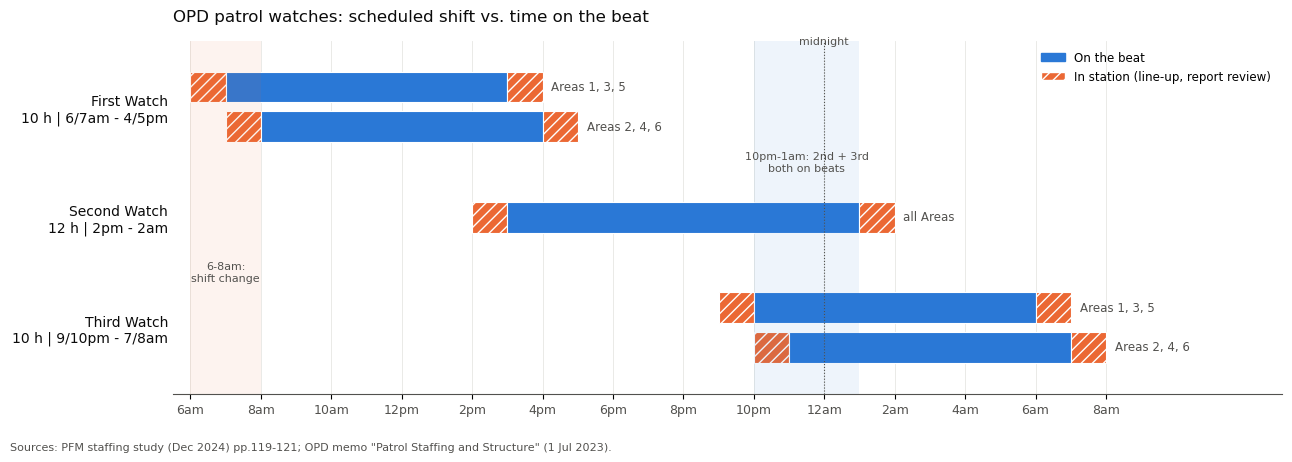

In [3]:
# Scheduled shift vs. hours on the beat. Hours run past 24 so overnight watches stay contiguous (31 = 7am next day).
#   Sources: PFM staffing study (Dec 2024) pp.119-121; OPD memo "Patrol Staffing and Structure" (1 Jul 2023).
ON_BEAT, IN_STATION = "#2a78d6", "#eb6834"
watches = {                                     # (row offset, start hour, end hour, Areas)
    "First Watch\n10 h | 6/7am - 4/5pm":  [(+.18, 6, 16, "Areas 1, 3, 5"), (-.18, 7, 17, "Areas 2, 4, 6")],
    "Second Watch\n12 h | 2pm - 2am":      [(0, 14, 26, "all Areas")],
    "Third Watch\n10 h | 9/10pm - 7/8am":  [(+.18, 21, 31, "Areas 1, 3, 5"), (-.18, 22, 32, "Areas 2, 4, 6")],
}

fig, ax = plt.subplots(figsize=(13, 4.6))
for row, (name, variants) in enumerate(reversed(list(watches.items()))):
    for dy, s, e, lab in variants:
        y = row + dy
        for left, width, color, hatch in [(s, 1, IN_STATION, "///"), (s + 1, e - s - 2, ON_BEAT, None), (e - 1, 1, IN_STATION, "///")]:
            ax.barh(y, width, left=left, height=.28, color=color, hatch=hatch, edgecolor="white", linewidth=.8)
        ax.text(e + .25, y, lab, va="center", ha="left", fontsize=8.5, color=MUTED)

ax.set_yticks(range(len(watches)), reversed(list(watches)), fontsize=10, color=INK)
ax.set_ylim(-.6, len(watches) - .4)
clock = lambda h: "12am" if h % 24 == 0 else "12pm" if h % 24 == 12 else f"{h % 12}{'am' if h % 24 < 12 else 'pm'}"
ticks = range(6, 33, 2)
ax.set_xticks(ticks, [clock(h) for h in ticks], fontsize=9, color=MUTED)
ax.set_xlim(5.5, 37)
ax.axvline(24, color=MUTED, lw=.8, ls=":")
ax.text(24, len(watches) - .45, "midnight", ha="center", va="bottom", fontsize=8, color=MUTED)
ax.axvspan(6, 8, color=IN_STATION, alpha=.08, lw=0)
ax.text(7, .5, "6-8am:\nshift change", ha="center", va="center", fontsize=8, color=MUTED)
ax.axvspan(22, 25, color=ON_BEAT, alpha=.08, lw=0)
ax.text(23.5, 1.5, "10pm-1am: 2nd + 3rd\nboth on beats", ha="center", va="center", fontsize=8, color=MUTED)

ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color(MUTED)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color=GRID, lw=.6); ax.set_axisbelow(True)
ax.legend(handles=[Patch(color=ON_BEAT, label="On the beat"),
                   Patch(facecolor=IN_STATION, hatch="///", edgecolor="white", label="In station (line-up, report review)")],
          loc="upper right", fontsize=8.5, frameon=False)
ax.set_title("OPD patrol watches: scheduled shift vs. time on the beat", loc="left", fontsize=12, color=INK, pad=14)
fig.text(.01, .005, "Sources: PFM staffing study (Dec 2024) pp.119-121; OPD memo \"Patrol Staffing and Structure\" (1 Jul 2023).",
         fontsize=8, color=MUTED, va="bottom")
fig.tight_layout(rect=(0, .05, 1, 1))
plt.show()

## 2. Officers assigned to patrol, by Area

Headcount from the "Number of officers assigned to patrol" table in each OPD staffing report to Council since the current Area boundaries (10 reports, Mar 2022 - Feb 2026; values in `opd_patrol_officers_by_area.csv`). Counts are permanent assignments and include officers on leave, so they run above the budget of 16 officers per watch per Area.

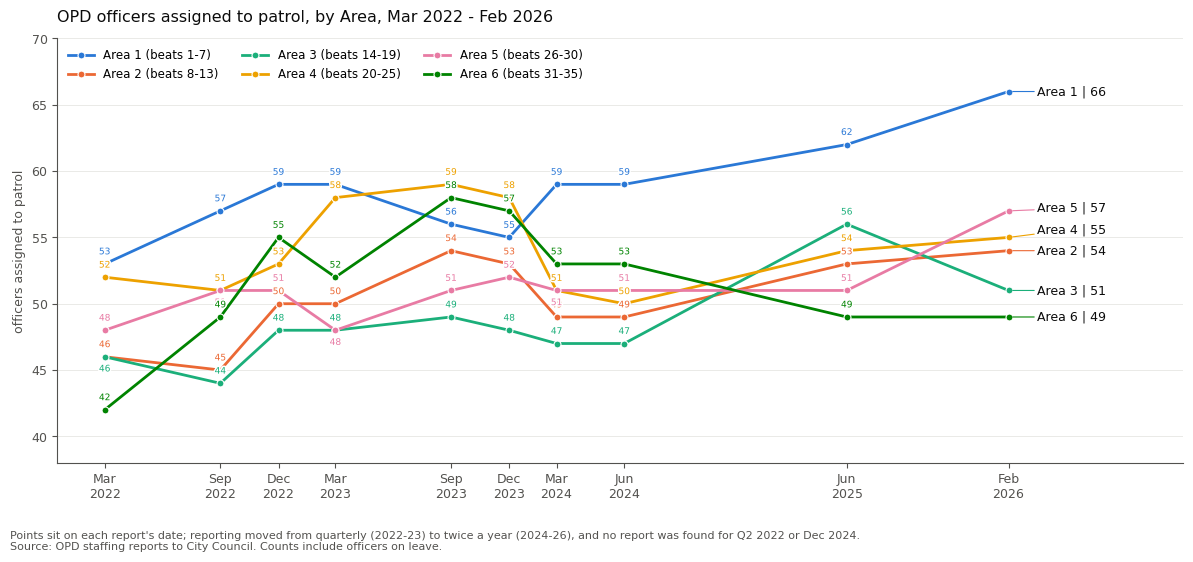

In [4]:
staff = pd.read_csv(DATA / "opd_patrol_officers_by_area.csv", parse_dates=["as_of"]).sort_values("as_of")
dates = sorted(staff["as_of"].unique())

fig, ax = plt.subplots(figsize=(12, 5.6))
placed, ends = {}, []
for a, g in staff.groupby("area"):
    x, y = g["as_of"], g["officers_assigned_to_patrol"]
    ax.plot(x, y, color=AREA_COLORS[a], lw=2, marker="o", ms=5, mec="white", mew=.8, label=f"Area {a} (beats {AREA_BEATS[a]})")
    for xi, yi in zip(x.iloc[:-1], y.iloc[:-1]):                 # point values; a tie on one date goes below the marker
        n = placed.get((xi, yi), 0)
        placed[(xi, yi)] = n + 1
        ax.annotate(f"{int(yi)}", (xi, yi), xytext=(0, 5.5 if n == 0 else -5.5), textcoords="offset points", ha="center",
                    va="bottom" if n == 0 else "top", fontsize=6.5, color=AREA_COLORS[a], path_effects=HALO, zorder=6)
    ends.append((y.iloc[-1], a, x.iloc[-1]))

ends.sort()
label_y = [ends[0][0]]
for y, _, _ in ends[1:]:
    label_y.append(max(y, label_y[-1] + 1.6))
for (y, a, x), yl in zip(ends, label_y):
    ax.annotate(f"Area {a} | {int(y)}", (x, y), xytext=(x + pd.Timedelta(days=45), yl), textcoords="data", va="center",
                fontsize=9, color=INK, arrowprops=dict(arrowstyle="-", color=AREA_COLORS[a], lw=.8, shrinkA=0, shrinkB=3))

ax.set_ylim(38, 70)
ax.set_xlim(pd.Timestamp("2022-01-15"), pd.Timestamp("2026-12-01"))
ax.set_xticks(dates, [pd.Timestamp(d).strftime("%b\n%Y") for d in dates], fontsize=8)
ax.set_ylabel("officers assigned to patrol", color=MUTED, fontsize=9)
style(ax, 9)
ax.legend(loc="upper left", fontsize=8.5, frameon=False, ncol=3, handlelength=2.2)
ax.set_title("OPD officers assigned to patrol, by Area, Mar 2022 - Feb 2026", loc="left", fontsize=11.5, color=INK, pad=12)
fig.text(.01, .005, "Points sit on each report's date; reporting moved from quarterly (2022-23) to twice a year (2024-26), and no report "
         "was found for Q2 2022 or Dec 2024.\nSource: OPD staffing reports to City Council. Counts include officers on leave.",
         fontsize=8, color=MUTED, va="bottom")
fig.tight_layout(rect=(0, .07, 1, 1))
plt.show()

## 3. Officers per shift and day

Each Area's headcount split across its shifts and days. The Area totals are reported; the split is derived:
- OPD budgets patrol evenly at 16 officers per watch per Area, 14 for Area 2 (PFM p.150), so each watch gets a third.
- Each watch has A and B sides of equal size that alternate days (PFM p.149), so a normal day fields one side: a sixth of the Area.
- On the Area's overlap day both sides work First and Third Watch, doubling those shifts. Second Watch never doubles.

Each report's headcount is assumed to hold until the next report; the last period runs to 30 Jun 2026, the end of the CAD data. The full table is `shift_days` (one row per report period, Area, shift and day); the latest period is shown.

In [5]:
EARLY = {1, 3, 5}                                       # Areas starting at 6am / 9pm; the others an hour later
SHIFTS = {"1st": ("06:00", "16:00", "07:00", "17:00"),
          "2nd": ("14:00", "02:00", "14:00", "02:00"),
          "3rd": ("21:00", "07:00", "22:00", "08:00")}
OVERLAP_DAY = {1: "Monday", 2: "Sunday", 3: "Saturday", 4: "Friday", 5: "Thursday", 6: "Friday"}   # OPD memo, 1 Jul 2023
DATA_END = pd.Timestamp("2026-06-30")

report_dates = sorted(staff["as_of"].unique())
valid_to = {d: pd.Timestamp(nxt) - pd.Timedelta(days=1) for d, nxt in zip(report_dates, report_dates[1:])}
valid_to[report_dates[-1]] = DATA_END

rows = []
for r in staff.itertuples():
    per_side = round(r.officers_assigned_to_patrol / 6, 2)
    late = 0 if r.area in EARLY else 2
    for w, t in SHIFTS.items():
        for day in DAYS:
            doubles = w != "2nd" and day == OVERLAP_DAY[r.area]
            rows.append({"valid_from": r.as_of.date(), "valid_to": valid_to[r.as_of].date(), "area": r.area, "beats": r.beats,
                         "shift_start": t[late], "shift_end": t[late + 1], "day": day,
                         "officers_assigned": round(per_side * (2 if doubles else 1), 2)})

shift_days = pd.DataFrame(rows)
shift_days["day"] = pd.Categorical(shift_days["day"], categories=DAYS, ordered=True)
shift_days = shift_days.sort_values(["valid_from", "area", "shift_start", "day"]).reset_index(drop=True)

latest = shift_days[shift_days["valid_from"] == shift_days["valid_from"].max()]
print(f"{len(shift_days):,} rows, {shift_days['valid_from'].nunique()} report periods. "
      f"Latest: {latest['valid_from'].iloc[0]} to {latest['valid_to'].iloc[0]}")
latest.pivot_table(index=["area", "shift_start", "shift_end"], columns="day", values="officers_assigned", observed=True)

1,260 rows, 10 report periods. Latest: 2026-02-28 to 2026-06-30


day                         Monday  Tuesday  Wednesday  Thursday  Friday  \
area shift_start shift_end                                                 
1    06:00       16:00       22.00    11.00      11.00     11.00   11.00   
     14:00       02:00       11.00    11.00      11.00     11.00   11.00   
     21:00       07:00       22.00    11.00      11.00     11.00   11.00   
2    07:00       17:00        9.00     9.00       9.00      9.00    9.00   
     14:00       02:00        9.00     9.00       9.00      9.00    9.00   
     22:00       08:00        9.00     9.00       9.00      9.00    9.00   
3    06:00       16:00        8.50     8.50       8.50      8.50    8.50   
     14:00       02:00        8.50     8.50       8.50      8.50    8.50   
     21:00       07:00        8.50     8.50       8.50      8.50    8.50   
4    07:00       17:00        9.17     9.17       9.17      9.17   18.34   
     14:00       02:00        9.17     9.17       9.17      9.17    9.17   
     22:00       08:00        9.17     9.17       9.17      9.17   18.34   
5    06:00       16:00        9.50     9.50       9.50     19.00    9.50   
     14:00       02:00        9.50     9.50       9.50      9.50    9.50   
     21:00       07:00        9.50     9.50       9.50     19.00    9.50   
6    07:00       17:00        8.17     8.17       8.17      8.17   16.34   
     14:00       02:00        8.17     8.17       8.17      8.17    8.17   
     22:00       08:00        8.17     8.17       8.17      8.17   16.34   

day                         Saturday  Sunday  
area shift_start shift_end                    
1    06:00       16:00         11.00   11.00  
     14:00       02:00         11.00   11.00  
     21:00       07:00         11.00   11.00  
2    07:00       17:00          9.00   18.00  
     14:00       02:00          9.00    9.00  
     22:00       08:00          9.00   18.00  
3    06:00       16:00         17.00    8.50  
     14:00       02:00          8.50    8.50  
     21:00       07:00         17.00    8.50  
4    07:00       17:00          9.17    9.17  
     14:00       02:00          9.17    9.17  
     22:00       08:00          9.17    9.17  
5    06:00       16:00          9.50    9.50  
     14:00       02:00          9.50    9.50  
     21:00       07:00          9.50    9.50  
6    07:00       17:00          8.17    8.17  
     14:00       02:00          8.17    8.17  
     22:00       08:00          8.17    8.17

## 4. Officers on duty by hour

Officers on the clock in each Area by hour, latest report, on a normal day (one side of each watch). Solid blocks are officers on the beats; hatched blocks are officers in the station for the first or last hour of their shift.

At 6am in Areas 1, 3 and 5 (7am in Areas 2, 4 and 6) every officer on duty is in the first or last hour of a shift: Third Watch is finishing and First Watch is starting. PFM reports this as a coverage gap (p.104); how many officers are actually out on the beats in that hour is not recorded. Other units and neighbouring Areas can still respond, and P1 calls can go to any unit citywide.

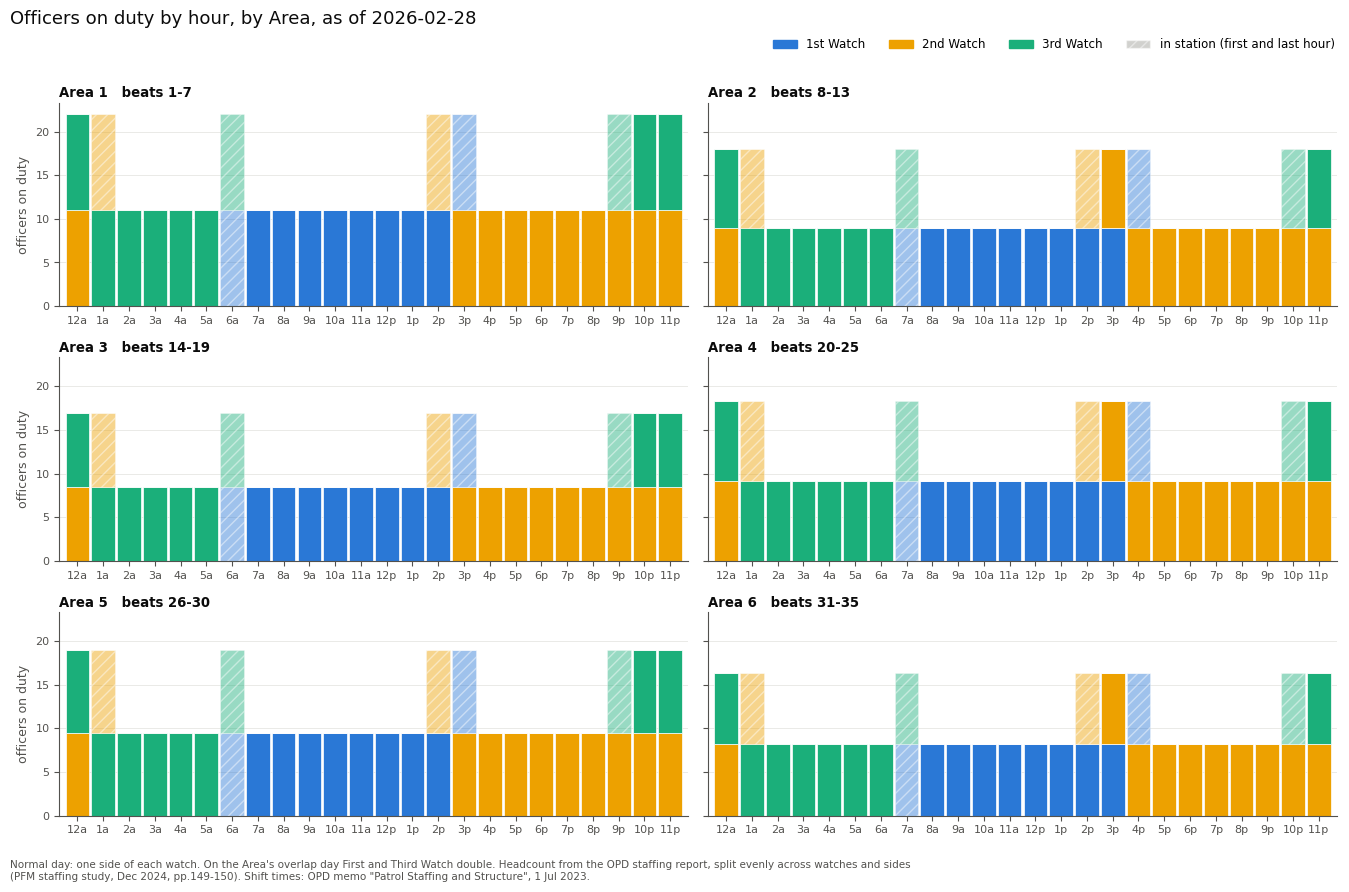

In [6]:
W_COL = {"1st": "#2a78d6", "2nd": "#eda100", "3rd": "#1baf7a"}
WATCH_OF = {6: "1st", 7: "1st", 14: "2nd", 21: "3rd", 22: "3rd"}
HOUR_LABEL = [f"{(h - 1) % 12 + 1}{'a' if h < 12 else 'p'}" for h in range(24)]       # 12a, 1a, ... 11p

grid = {}                                               # Area -> watch -> officers on the beat / in station, by hour
for a, g in latest.groupby("area"):
    d = {w: {"beat": np.zeros(24), "stn": np.zeros(24)} for w in W_COL}
    for (s, e), gg in g.groupby(["shift_start", "shift_end"]):
        sh, dur = int(s[:2]), (int(e[:2]) - int(s[:2])) % 24
        w, n = WATCH_OF[sh], gg["officers_assigned"].min()
        for i in range(dur):
            d[w]["stn" if i in (0, dur - 1) else "beat"][(sh + i) % 24] += n
    grid[a] = d

ymax = max(sum(d[w]["beat"] + d[w]["stn"] for w in W_COL).max() for d in grid.values())
fig, axes = plt.subplots(3, 2, figsize=(13.5, 8.8), sharex=True, sharey=True)
for ax, a in zip(axes.flat, sorted(grid)):
    d, bottom = grid[a], np.zeros(24)
    for part, kw in [("beat", {}), ("stn", {"alpha": .45, "hatch": "///"})]:      # solid blocks on the baseline, hatched on top
        for w in W_COL:
            ax.bar(range(24), d[w][part], bottom=bottom, width=.92, color=W_COL[w], edgecolor="white", lw=.5, zorder=2, **kw)
            bottom = bottom + d[w][part]
    ax.set_title(f"Area {a}   beats {AREA_BEATS[a]}", loc="left", fontsize=9.5, fontweight="bold", color=INK, pad=4)
    ax.set_xlim(-.7, 23.7); ax.set_ylim(0, ymax * 1.06)
    ax.set_xticks(range(24), HOUR_LABEL, fontsize=6.2)
    style(ax)
    ax.tick_params(labelbottom=True)
for ax in axes[:, 0]:
    ax.set_ylabel("officers on duty", color=MUTED, fontsize=9)

fig.legend(handles=[Patch(color=W_COL[w], label=f"{w} Watch") for w in W_COL]
                   + [Patch(facecolor="#9a9a94", alpha=.45, hatch="///", edgecolor="white", label="in station (first and last hour)")],
           loc="upper right", bbox_to_anchor=(.995, .975), fontsize=8.5, frameon=False, ncol=4)
fig.suptitle(f"Officers on duty by hour, by Area, as of {latest['valid_from'].iloc[0]}", x=.006, ha="left", fontsize=13, color=INK, y=.995)
fig.text(.006, .004, "Normal day: one side of each watch. On the Area's overlap day First and Third Watch double. Headcount from the OPD "
         "staffing report, split evenly across watches and sides\n(PFM staffing study, Dec 2024, pp.149-150). Shift times: OPD memo "
         "\"Patrol Staffing and Structure\", 1 Jul 2023.", fontsize=7.5, color=MUTED, va="bottom")
fig.tight_layout(rect=(0, .04, 1, .963))
plt.show()

## 5. Response time by hour, by Area and year

Median response time by the hour the call came in: one figure per priority, one panel per Area, one line per year. P1 is in minutes; P2 and P3, which mostly wait in the queue, are in hours. Hours with fewer than 20 calls are left blank. P0 is too rare to chart by hour (see the table below).

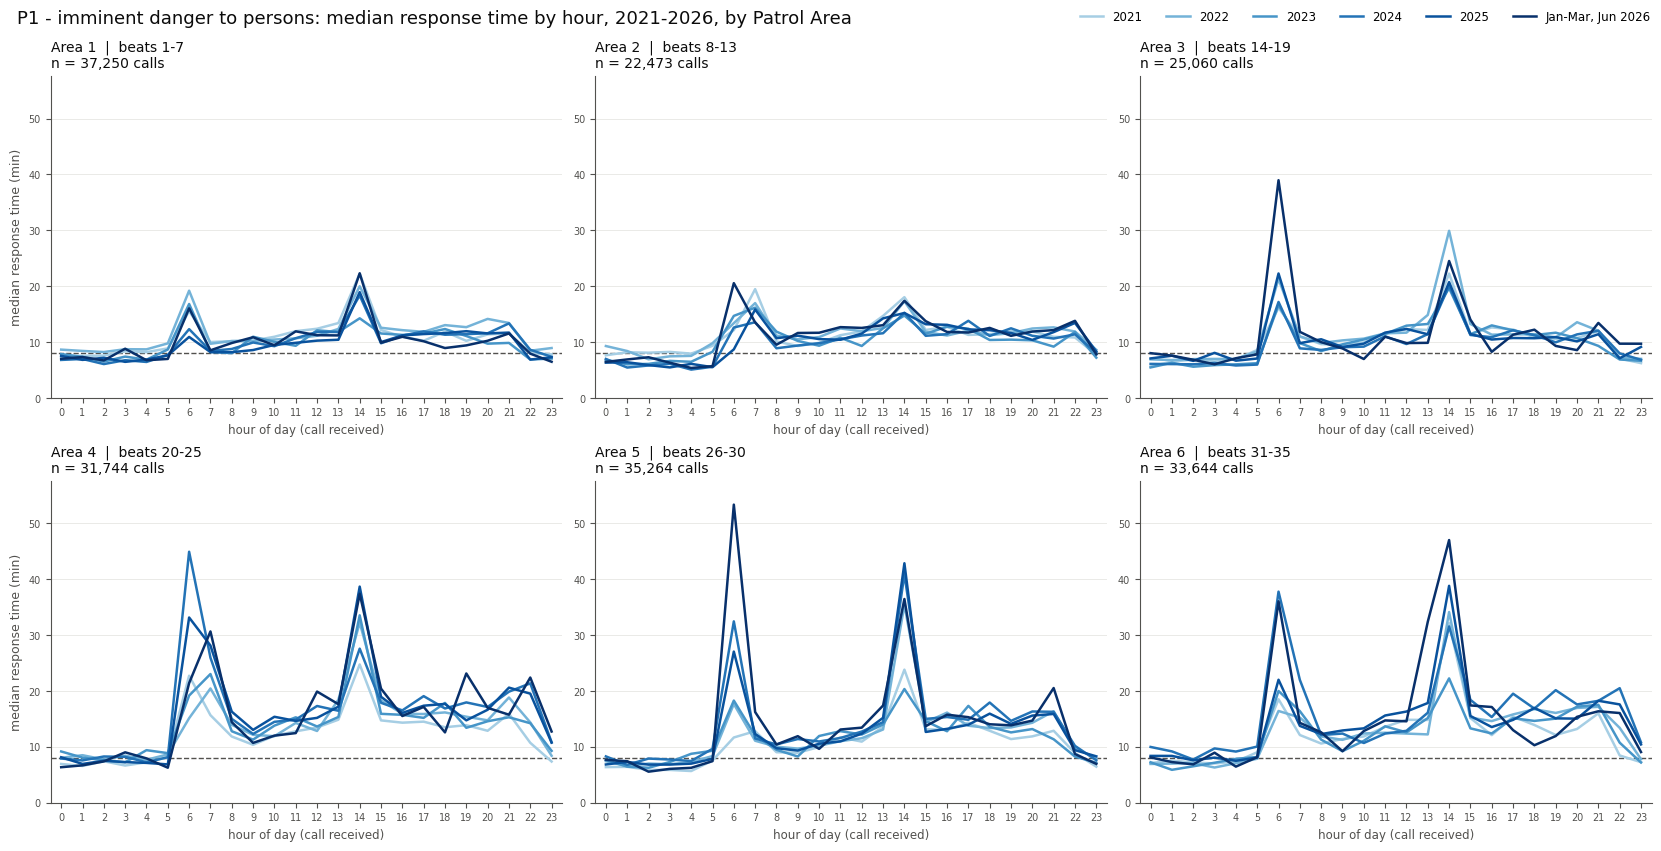

P1: median 213 calls per point; 0 of 864 points under 20 calls, not drawn


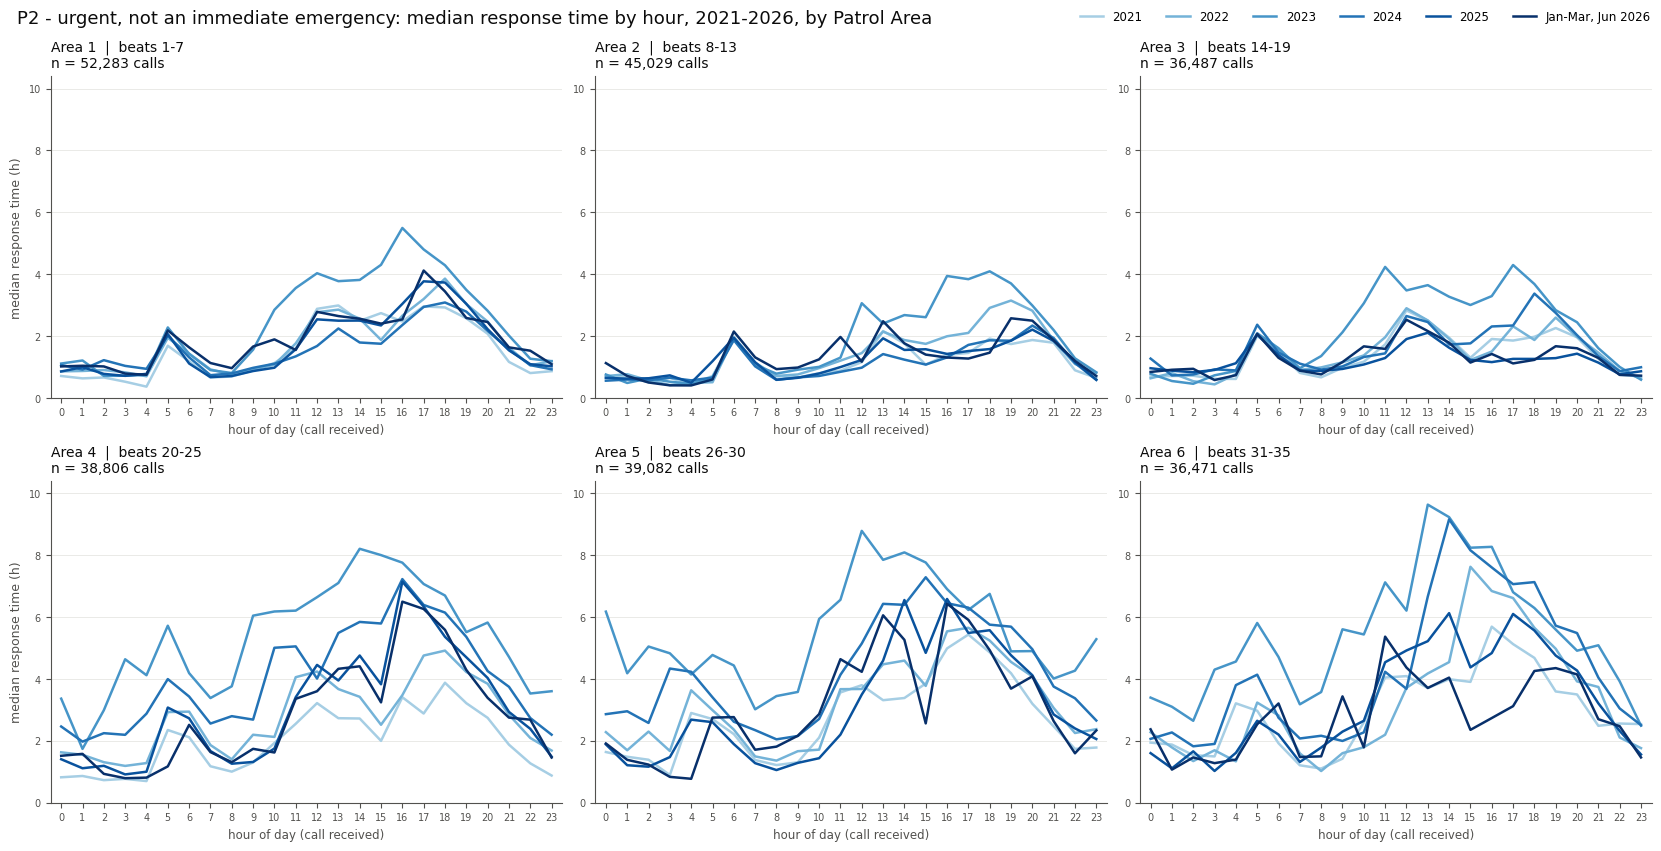

P2: median 284 calls per point; 0 of 864 points under 20 calls, not drawn


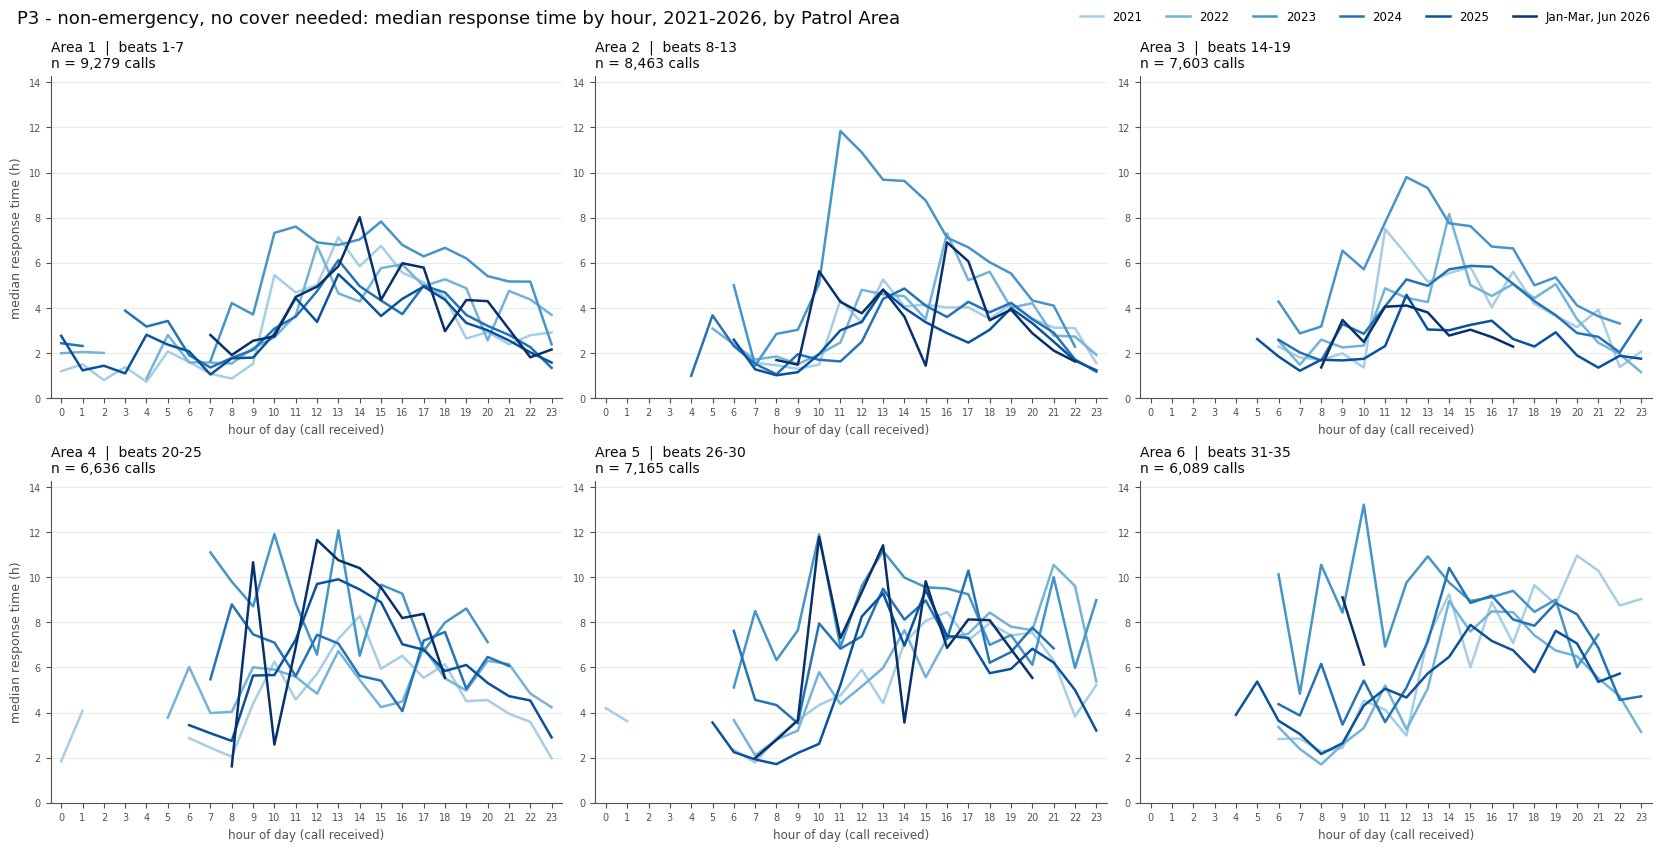

P3: median 45 calls per point; 216 of 863 points under 20 calls, not drawn


median response time (min), by Area               1      2      3      4  \
priority                                year                               
P0 - officer safety or catastrophe      2021   25.3  160.2    5.1    NaN   
                                        2022    4.9    9.1    NaN    NaN   
                                        2023   14.7    NaN   16.2    NaN   
                                        2024    5.2    8.2    5.7    NaN   
                                        2025    9.9   10.6    9.4   10.5   
                                        2026    NaN    NaN    NaN    NaN   
P1 - imminent danger to persons         2021   10.4   11.0    9.8   11.9   
                                        2022   11.0   11.3   10.2   13.1   
                                        2023    9.7   10.2    9.6   13.4   
                                        2024    9.5    9.7    9.2   14.6   
                                        2025    9.3   10.3    9.9   14.3   
                                        2026    9.6   11.3    9.6   14.2   
P2 - urgent, not an immediate emergency 2021   81.4   66.1   81.1  117.0   
                                        2022   99.1   78.9   83.8  169.8   
                                        2023  161.1  113.8  137.3  347.4   
                                        2024   91.2   62.6   96.1  251.0   
                                        2025   91.5   70.1   71.2  168.8   
                                        2026  110.8   74.2   75.2  160.1   
P3 - non-emergency, no cover needed     2021  182.2  179.1  221.1  282.2   
                                        2022  210.1  184.4  204.4  310.5   
                                        2023  359.8  372.0  360.2  511.4   
                                        2024  193.6  163.1  209.0  364.1   
                                        2025  174.9  155.6  140.7  339.1   
                                        2026  211.1  172.0  150.9  375.2   

median response time (min), by Area               5      6      n  
priority                                year                       
P0 - officer safety or catastrophe      2021    NaN   11.2      8  
                                        2022    7.7    NaN      6  
                                        2023    NaN   15.2      5  
                                        2024  411.6    NaN     14  
                                        2025   28.0   16.8     20  
                                        2026   27.2    NaN      2  
P1 - imminent danger to persons         2021   10.1   11.0  43630  
                                        2022   11.1   12.0  41994  
                                        2023   11.0   11.6  15595  
                                        2024   12.0   14.1  39196  
                                        2025   11.1   13.2  35175  
                                        2026   11.2   12.6   9845  
P2 - urgent, not an immediate emergency 2021  157.6  176.8  60851  
                                        2022  188.2  187.1  55023  
                                        2023  349.7  356.8  30957  
                                        2024  263.1  251.7  43904  
                                        2025  170.0  197.0  42882  
                                        2026  170.7  172.5  14541  
P3 - non-emergency, no cover needed     2021  338.1  338.6  10202  
                                        2022  322.6  326.0   9698  
                                        2023  515.8  539.8   5884  
                                        2024  420.3  401.0   7294  
                                        2025  321.4  314.1   9029  
                                        2026  414.7  399.6   3128

In [7]:
YEARS = sorted(timed["year"].unique())
YEAR_COLORS = dict(zip(YEARS, plt.cm.Blues(np.linspace(.35, 1, len(YEARS)))))      # light = earliest
year_label = {y: period(timed.loc[timed["year"] == y, "event_time"]) for y in YEARS}
UNIT = {1: ("min", 1), 2: ("h", 60), 3: ("h", 60)}
MIN_CALLS = 20                                          # hourly medians from fewer calls are not drawn

for p in [1, 2, 3]:
    unit, scale = UNIT[p]
    d = timed[timed["priority"] == p]
    med = d.groupby(["area", "year", "hour"])["response_min"].median() / scale
    cnt = d.groupby(["area", "year", "hour"]).size()
    med = med.where(cnt >= MIN_CALLS)
    fig, axes = plt.subplots(2, 3, figsize=(16.5, 8.4), sharex=True, sharey=True, layout="constrained")
    for ax, a in zip(axes.flat, AREA_BEATS):
        if p == 1:
            ax.axhline(SLA, color=MUTED, ls="--", lw=1, zorder=1)
        for y in YEARS:
            ax.plot(range(24), med.loc[(a, y)].reindex(range(24)), color=YEAR_COLORS[y], lw=1.8, zorder=3)
        ax.set_title(f"Area {a}  |  beats {AREA_BEATS[a]}\nn = {int(cnt.loc[a].sum()):,} calls", loc="left", fontsize=10, color=INK)
        ax.set_ylim(0, med.max() * 1.08)
        hour_axis(ax)
        style(ax, 7)
        ax.tick_params(labelbottom=True, labelleft=True)
    for ax in axes[:, 0]:
        ax.set_ylabel(f"median response time ({unit})", fontsize=9, color=MUTED)
    fig.legend(handles=[plt.Line2D([], [], color=YEAR_COLORS[y], lw=1.8, label=year_label[y]) for y in YEARS],
               loc="outside upper right", ncol=len(YEARS), fontsize=8.5, frameon=False)
    fig.suptitle(f"{PRIORITY_LABELS[p]}: median response time by hour, 2021-2026, by Patrol Area",
                 ha="left", x=.007, fontsize=13, color=INK)
    plt.show()
    print(f"P{p}: median {int(cnt.median())} calls per point; {(cnt < MIN_CALLS).sum()} of {len(cnt)} points under {MIN_CALLS} calls, not drawn")

summary = timed.pivot_table(index=["priority", "year"], columns="area", values="response_min", aggfunc="median").round(1)
summary["n"] = timed.groupby(["priority", "year"]).size()
summary.rename(index=PRIORITY_LABELS, level="priority").rename_axis(columns="median response time (min), by Area")

## 6. Call volume and response time by hour and weekday

One figure per Area, all years pooled. For each weekday, top: average calls per day by priority, from all cleaned calls whether or not an arrival was logged; middle: P1 median response time (minutes); bottom: P2 and P3 median response time (hours). Volume shares one scale across all Areas; response axes are scaled per Area. Hours with fewer than 20 calls are left blank.

P0: 108 calls in total, 0.01 a day per Area; not drawn


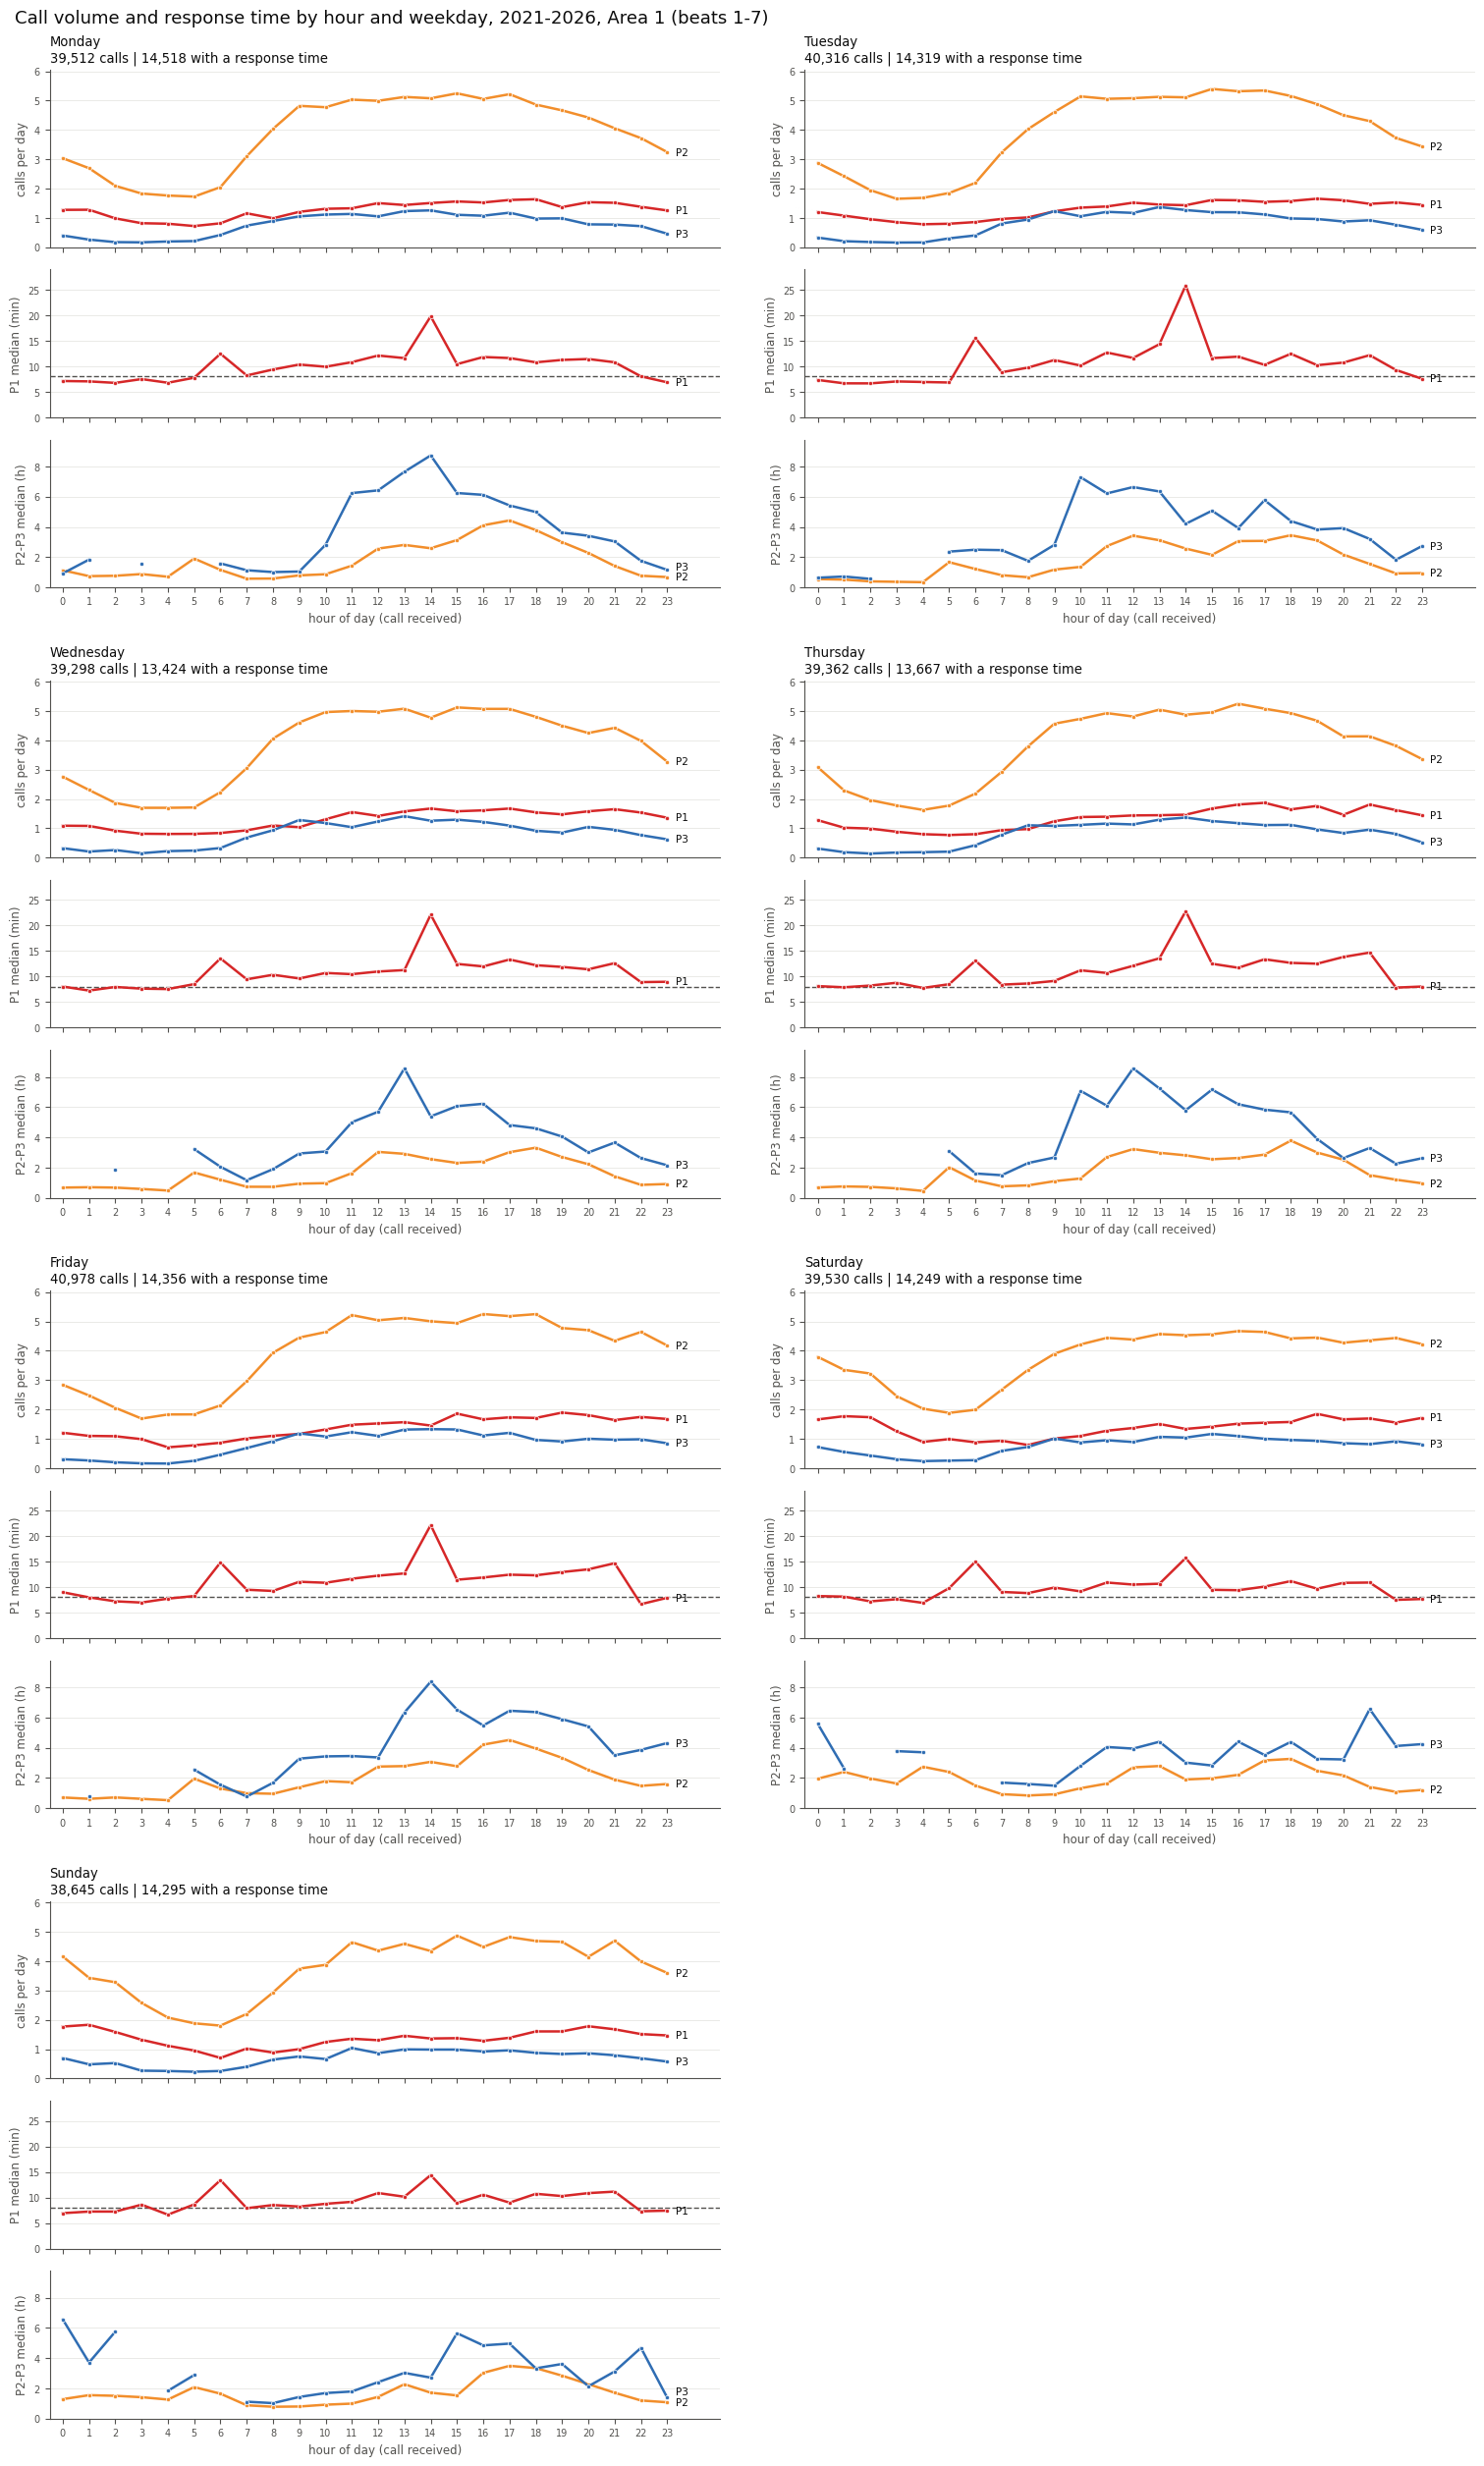

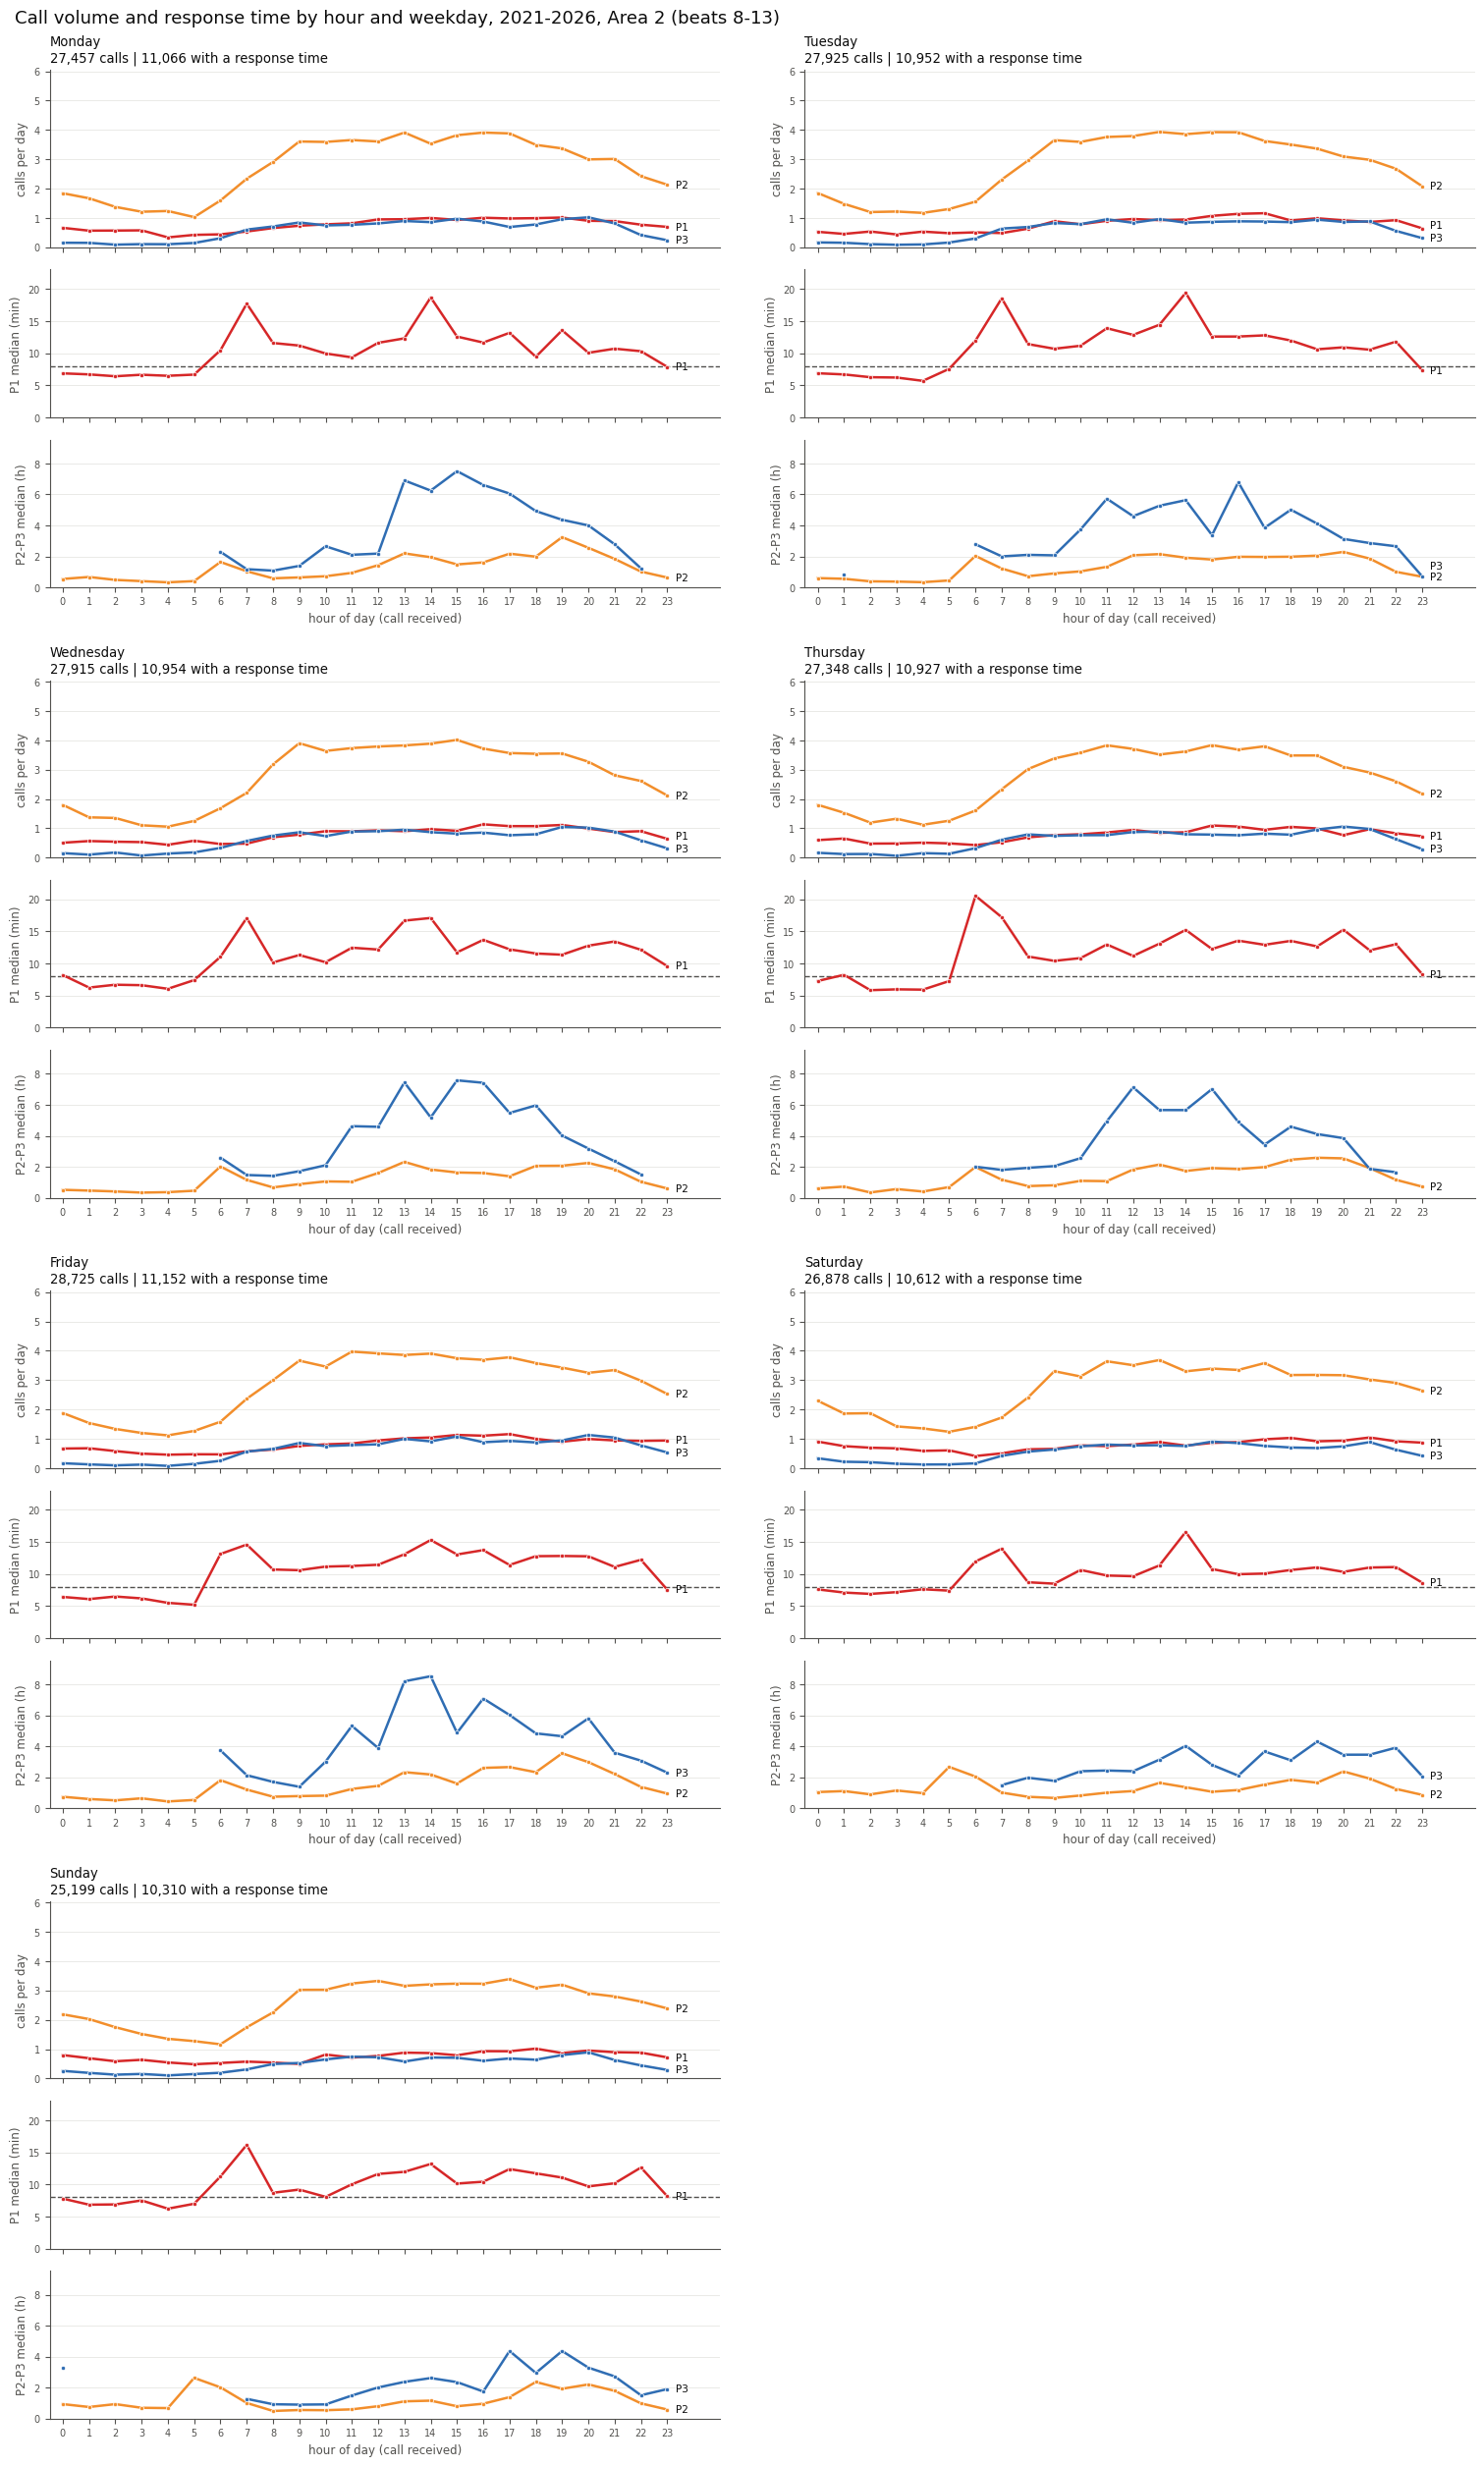

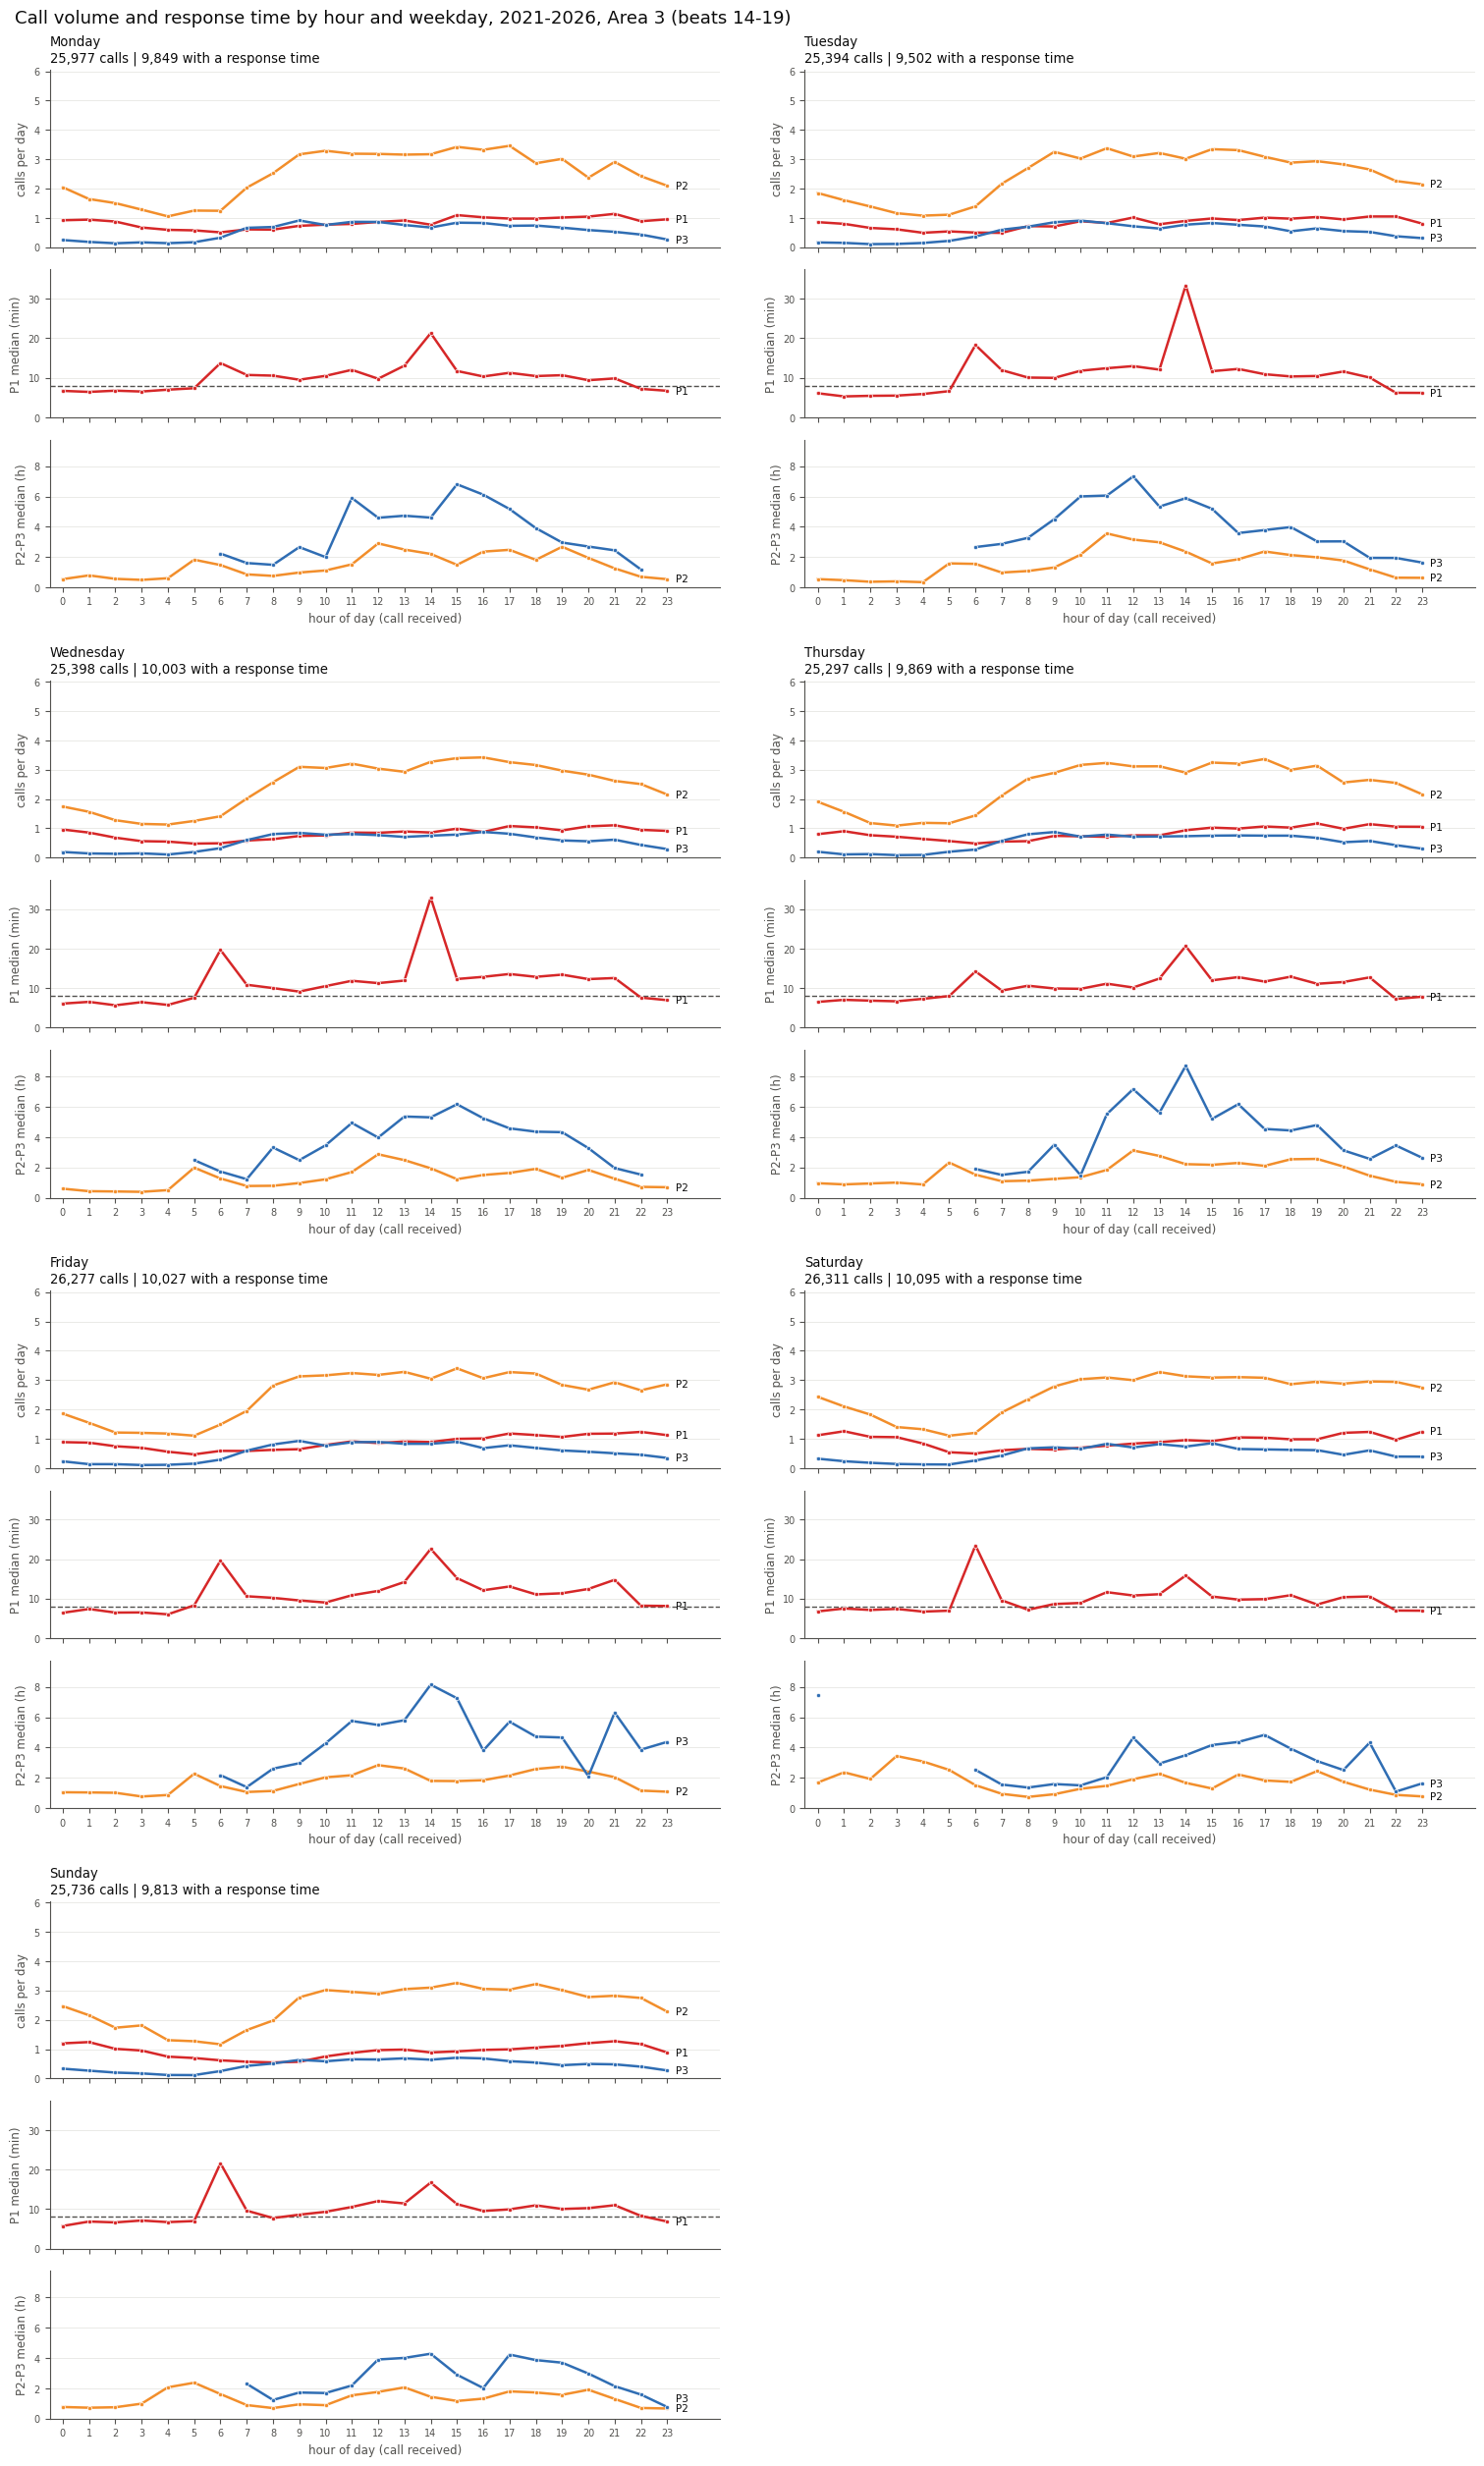

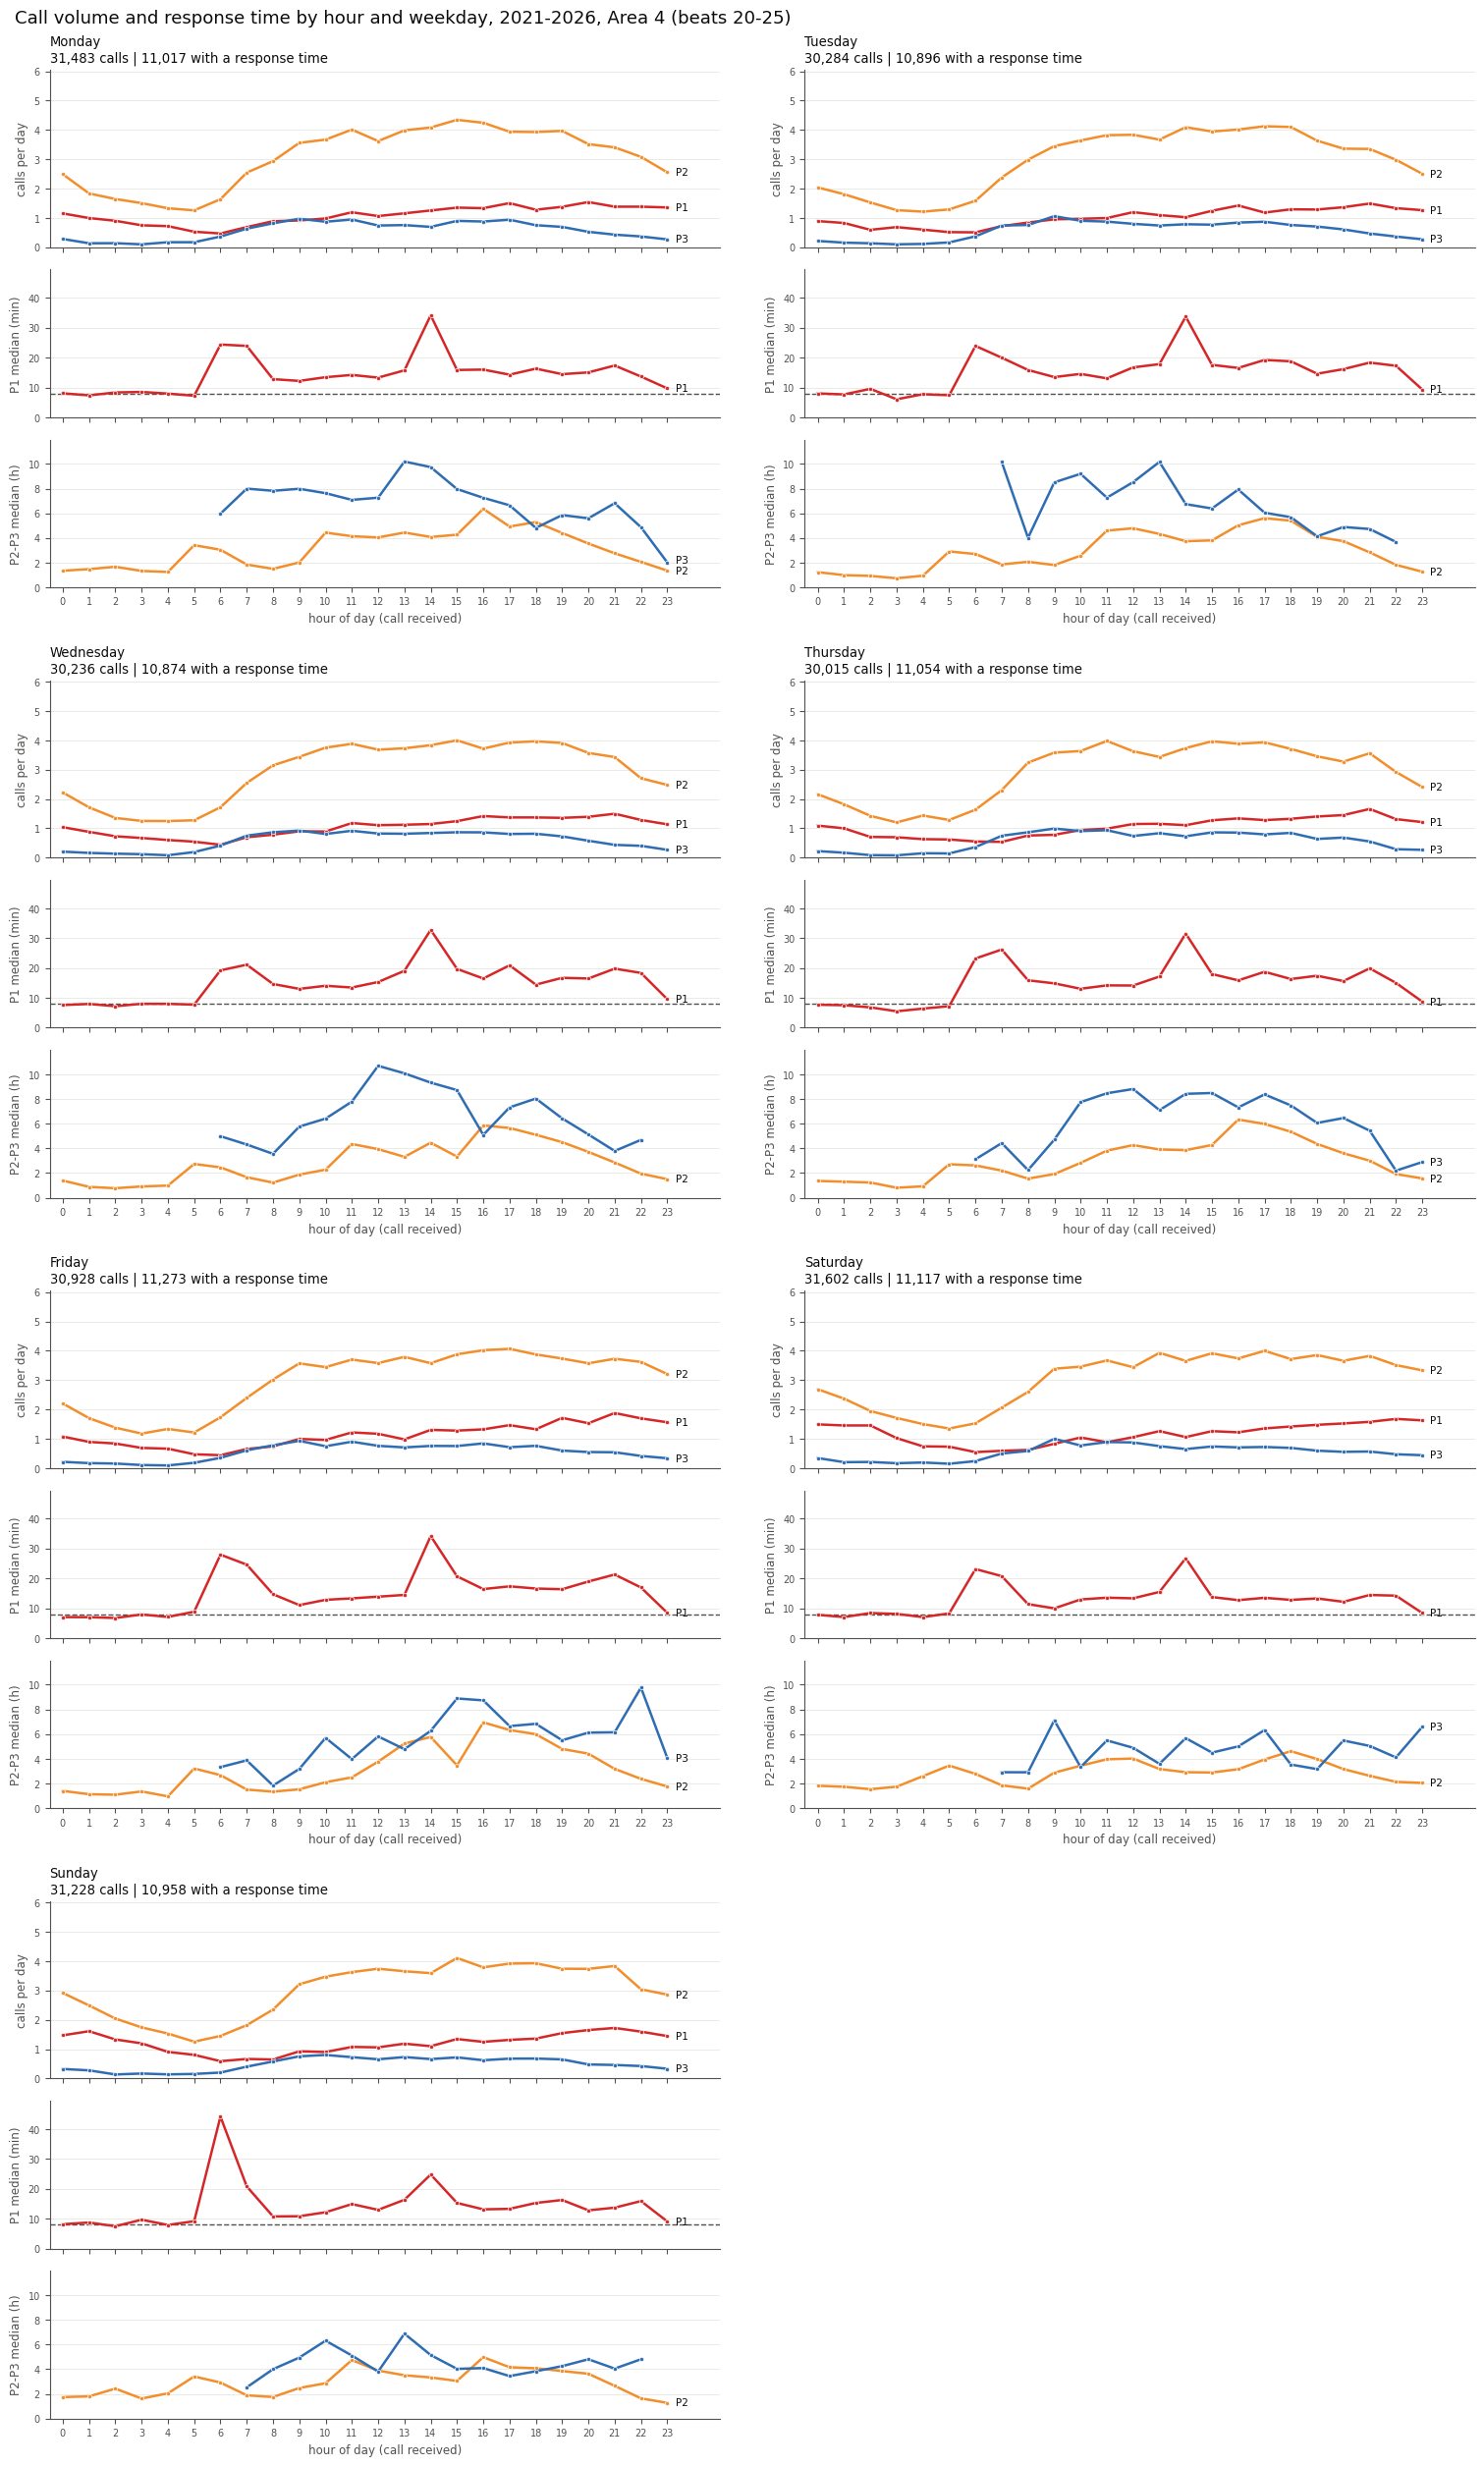

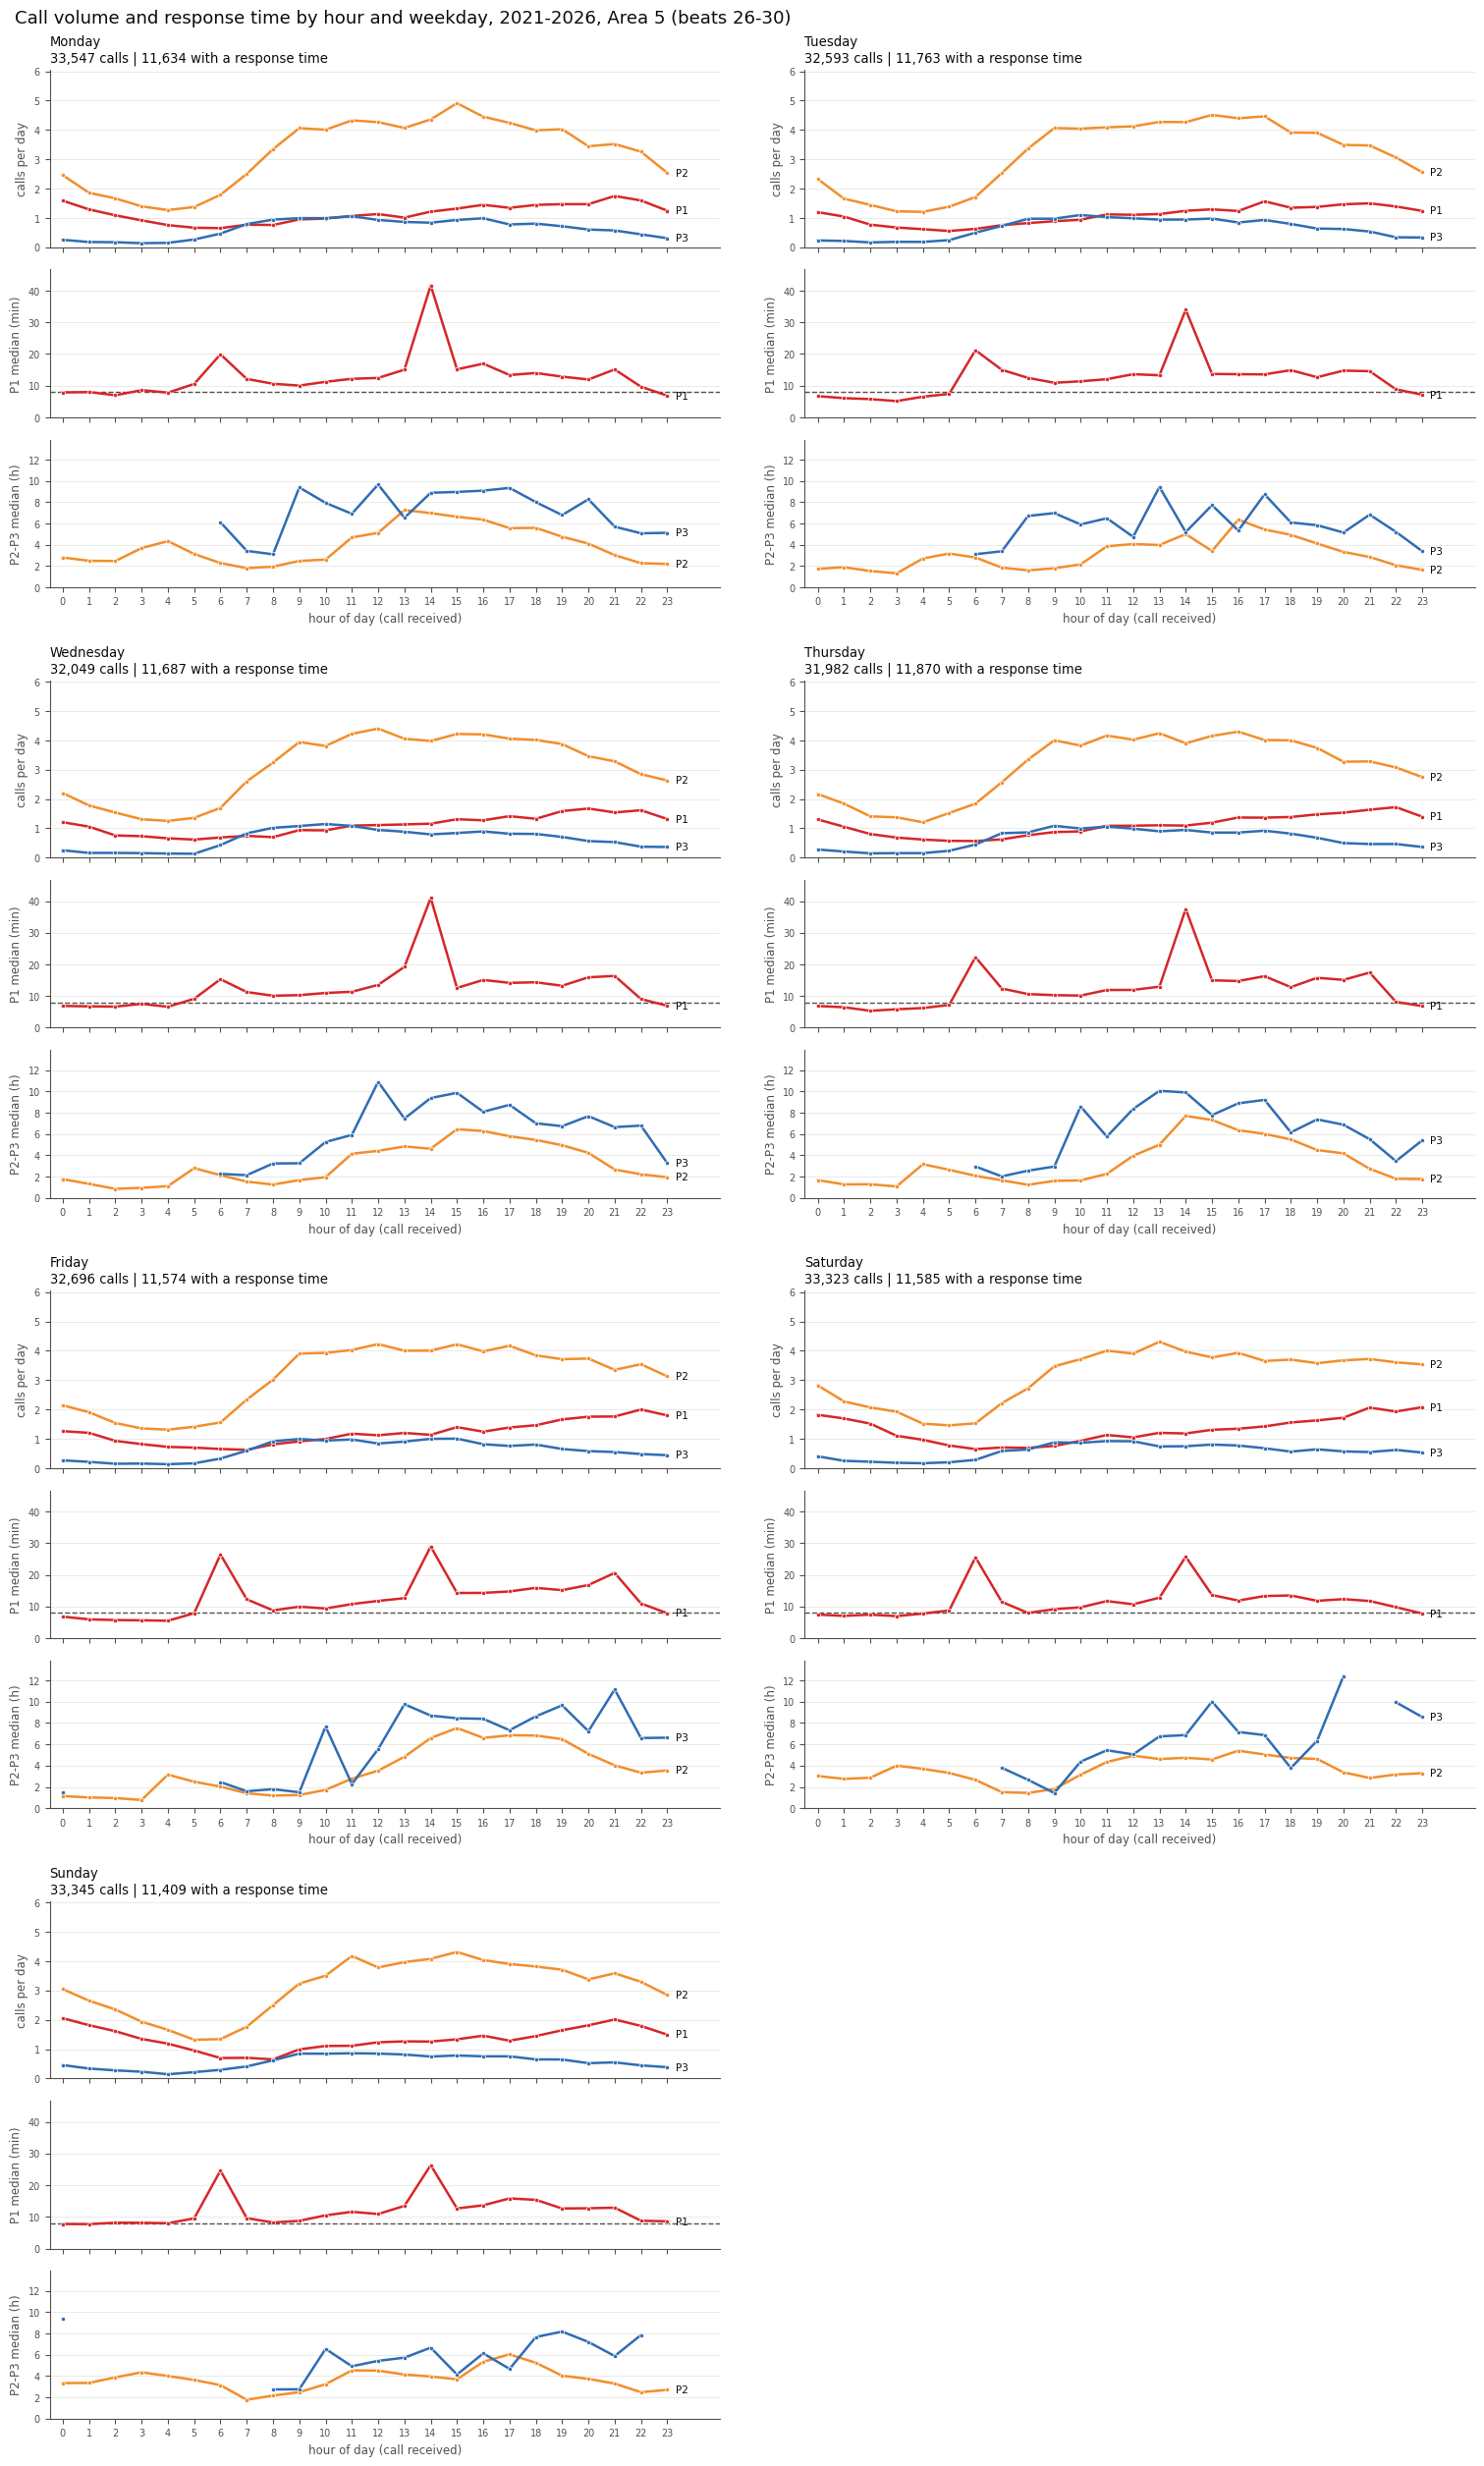

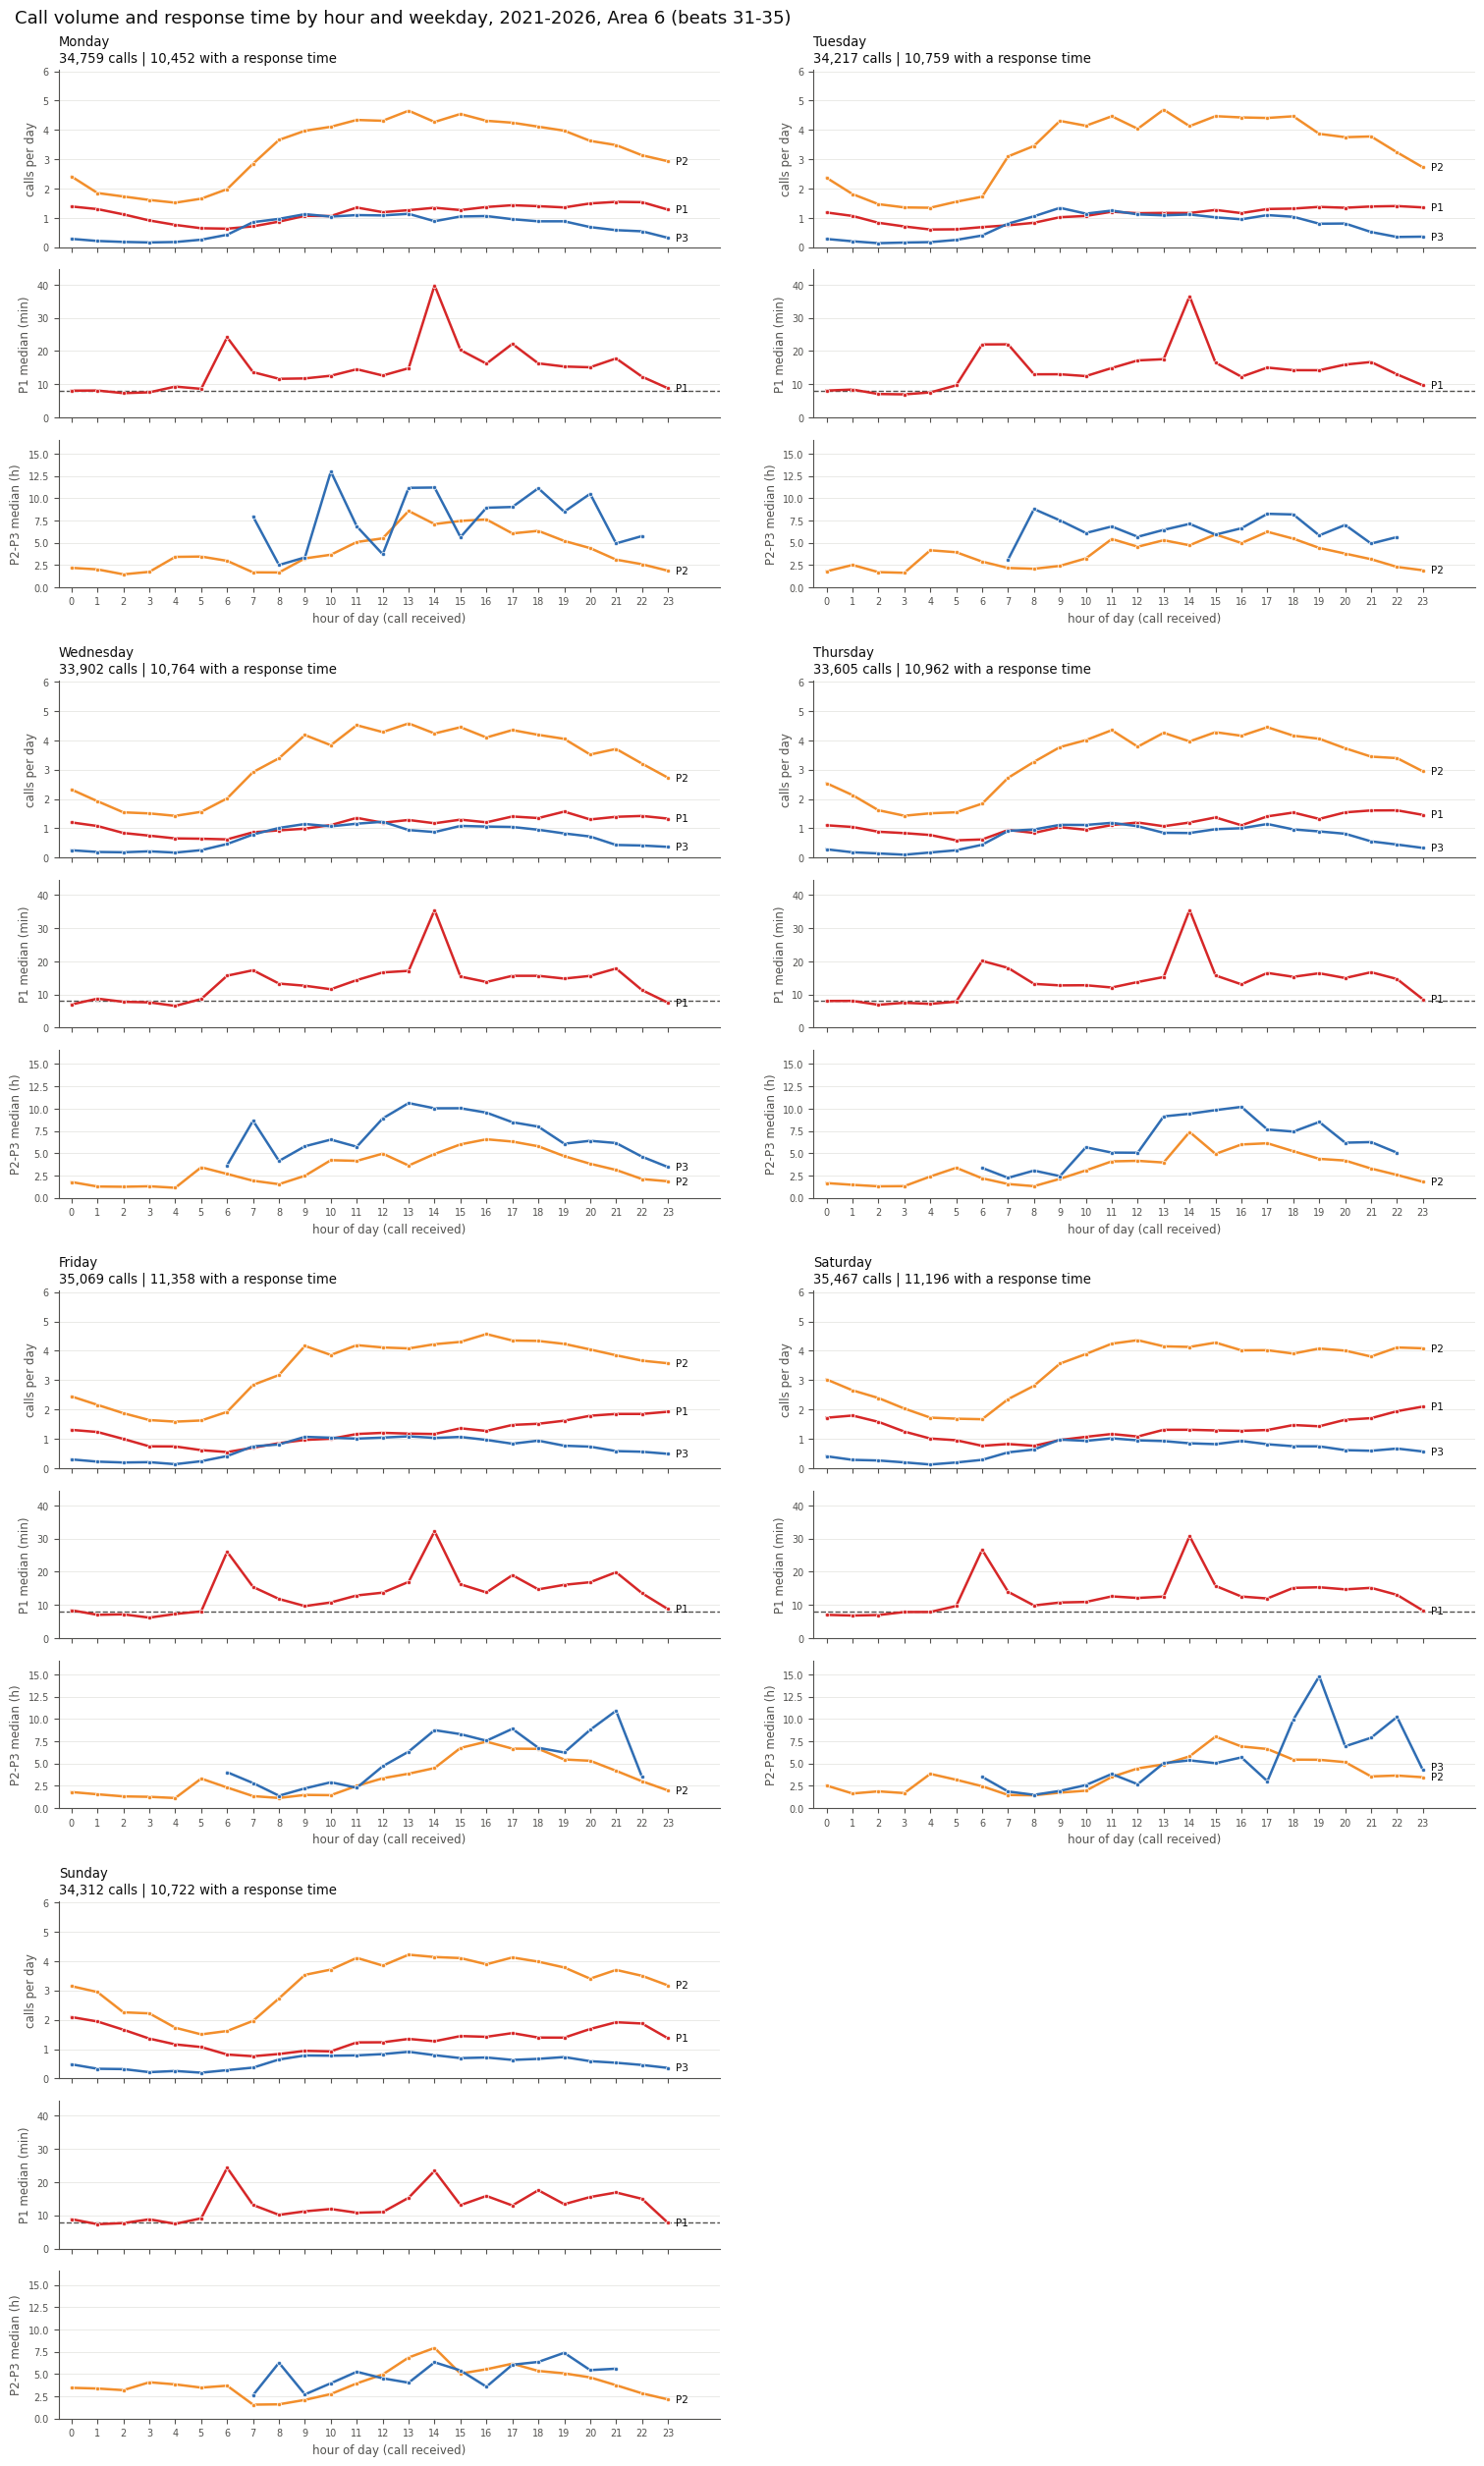

priority        calls_per_day  P1 median min  P2 median h  P3 median h
area dow                                                              
1    Monday             141.6            9.7          1.5          3.3
     Tuesday            144.5           10.1          1.5          3.9
     Wednesday          141.9           10.6          1.4          3.6
     Thursday           142.1           10.8          1.6          4.2
     Friday             147.4           10.6          1.9          3.9
     Saturday           142.2            9.4          1.8          3.0
     Sunday             139.0            9.0          1.6          2.5
2    Monday              98.4           10.2          1.1          3.2
     Tuesday            100.1           11.1          1.2          3.4
     Wednesday          100.8           11.2          1.2          3.6
     Thursday            98.7           11.5          1.3          3.4
     Friday             103.3           10.8          1.4          3.9
     Saturday            96.7            9.7          1.2          2.8
     Sunday              90.6            9.8          1.0          2.1
3    Monday              93.1            9.4          1.3          3.5
     Tuesday             91.0            9.7          1.4          3.8
     Wednesday           91.7           10.3          1.3          3.3
     Thursday            91.3           10.2          1.7          3.8
     Friday              94.5           10.6          1.7          4.3
     Saturday            94.6            9.0          1.5          2.9
     Sunday              92.6            9.0          1.2          2.5
4    Monday             112.8           13.3          3.2          6.6
     Tuesday            108.5           14.5          3.0          6.2
     Wednesday          109.2           14.2          2.8          6.3
     Thursday           108.4           13.7          3.0          6.1
     Friday             111.3           13.5          3.2          5.5
     Saturday           113.7           11.7          2.8          4.6
     Sunday             112.3           12.8          2.8          4.5
5    Monday             120.2           11.6          3.8          7.6
     Tuesday            116.8           11.5          3.1          6.1
     Wednesday          115.7           11.5          3.2          6.7
     Thursday           115.5           10.8          3.0          6.2
     Friday             117.6           11.0          3.2          5.3
     Saturday           119.9           10.2          3.6          6.3
     Sunday             119.9           10.8          3.7          5.2
6    Monday             124.6           13.0          4.0          7.8
     Tuesday            122.6           13.0          3.8          6.7
     Wednesday          122.4           12.8          3.5          7.0
     Thursday           121.3           12.6          3.3          6.1
     Friday             126.1           12.4          3.3          4.7
     Saturday           127.6           11.2          3.6          4.4
     Sunday             123.4           11.7          3.9          5.4

In [8]:
VOL_PRIOS = [1, 2, 3]                                   # P0 averages well under one call a day per Area
ndays = calls[["date", "dow"]].drop_duplicates()["dow"].value_counts().sort_index()      # days of each weekday in the data
vol = (calls[calls["priority"].isin(VOL_PRIOS)].groupby(["area", "dow", "hour", "priority"]).size()
            .unstack("priority").reindex(columns=VOL_PRIOS).fillna(0))
vol = vol.div(vol.index.get_level_values("dow").map(ndays), axis=0)
by_hour = timed[timed["priority"].isin(VOL_PRIOS)].groupby(["area", "dow", "hour", "priority"])["response_min"]
med = by_hour.median().where(by_hour.size() >= MIN_CALLS).unstack("priority")
med[[2, 3]] = med[[2, 3]] / 60
received = calls.groupby(["area", "dow"]).size()
n_timed = timed.groupby(["area", "dow"]).size()

VMAX = vol.max().max() * 1.12
P1_MAX = (med[1].groupby("area").max() * 1.12).to_dict()
P23_MAX = (med[[2, 3]].max(axis=1).groupby("area").max() * 1.12).to_dict()
print(f"P0: {(calls['priority'] == 0).sum():,} calls in total, "
      f"{(calls['priority'] == 0).sum() / ndays.sum() / len(AREA_BEATS):.2f} a day per Area; not drawn")

def end_labels(ax, items, gap):
    """labels at the line ends, nudged apart"""
    items = sorted(items)
    ys = [items[0][0]]
    for y, _ in items[1:]:
        ys.append(max(y, ys[-1] + gap))
    for y, (_, txt) in zip(ys, items):
        ax.annotate(txt, (23, y), xytext=(6, 0), textcoords="offset points", va="center", fontsize=7.5, color=INK)

def lines(ax, frame, prios, ymax, ylabel):
    for p in prios:
        ax.plot(range(24), frame[p], color=PRIORITY_COLORS[p], lw=1.8, marker="o", ms=3, mec="white", mew=.5, clip_on=False)
    end_labels(ax, [(frame[p].iloc[23], f"P{p}") for p in prios], ymax * .07)
    ax.set_ylim(0, ymax)
    ax.set_ylabel(ylabel, fontsize=8.5, color=MUTED)
    hour_axis(ax)
    ax.set_xlim(-.5, 25)
    style(ax, 7)

for a in AREA_BEATS:
    fig = plt.figure(figsize=(15, 25), layout="constrained")
    fig.suptitle(f"Call volume and response time by hour and weekday, 2021-2026, Area {a} (beats {AREA_BEATS[a]})",
                 ha="left", x=.006, fontsize=13, color=INK)
    sfs = fig.subfigures(4, 2, hspace=.02, wspace=.05)
    for dow in range(7):
        ax_v, ax_1, ax_23 = sfs[dow // 2, dow % 2].subplots(3, 1, sharex=True, height_ratios=[1.2, 1, 1])
        v = vol.loc[(a, dow)].reindex(range(24)).fillna(0)
        r = med.loc[(a, dow)].reindex(range(24))
        lines(ax_v, v, VOL_PRIOS, VMAX, "calls per day")
        lines(ax_1, r, [1], P1_MAX[a], "P1 median (min)")
        ax_1.axhline(SLA, color=MUTED, ls="--", lw=1, zorder=1)
        lines(ax_23, r, [2, 3], P23_MAX[a], "P2-P3 median (h)")
        for ax in (ax_v, ax_1):
            ax.tick_params(labelbottom=False)
            ax.set_xlabel("")
        ax_v.set_title(f"{DAYS[dow]}\n{int(received[(a, dow)]):,} calls | {int(n_timed[(a, dow)]):,} with a response time",
                       loc="left", fontsize=9.5, color=INK)
    for ax in sfs[3, 1].subplots(3, 1):
        ax.set_axis_off()
    plt.show()

table = timed[timed["priority"].isin(VOL_PRIOS)].groupby(["area", "dow", "priority"])["response_min"].median().unstack("priority")
table[[2, 3]] = table[[2, 3]] / 60
table = table.round(1).rename(columns=lambda p: f"P{p} median {'min' if p == 1 else 'h'}")
table.insert(0, "calls_per_day", (received / received.index.get_level_values("dow").map(ndays)).round(1))
table.rename(index=dict(enumerate(DAYS)), level="dow")

## 7. Call volume, officers on duty and response time, by hour

Demand, supply and response through the day for each Area. Each line is divided by its own average over the 24 hours, so all four share one axis: 1 is a typical hour, 1.5 is 50% above it. Real values are in each panel title and in the table below.
- **Calls:** cleaned P0-P3 calls by the hour received, averaged over 2021-2026.
- **Officers:** officers on duty from section 3, averaged over the week (overlap days included) and over the staffing reports from Mar 2022 to Jun 2026, weighted by how long each applied. **Dashed hours** include officers in the first or last hour of their shift; PFM says these are spent in the station, but how strictly that holds is not recorded, so they are counted as on duty.
- **Response time:** median by the hour the call came in, 2021-2026, for P1 and for P2-P3 together (P3 follows the same daily pattern as P2). P0 is too rare to chart by hour.

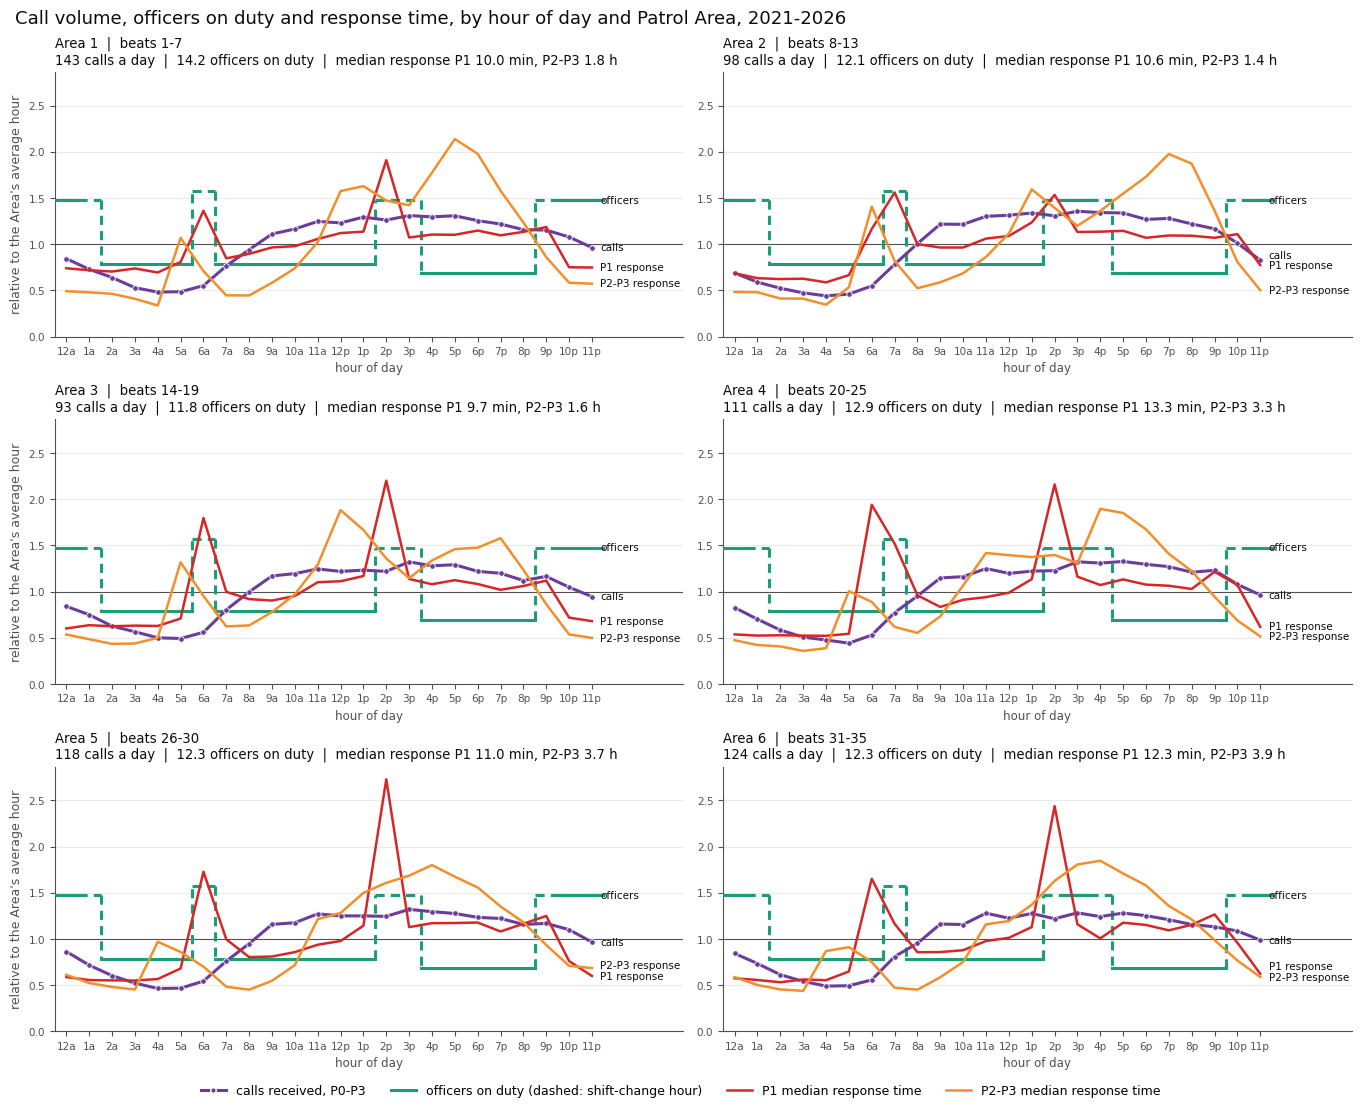

area              1                                                \
     calls per hour officers on duty P1 median min P2-P3 median h   
hour                                                                
0               5.0             21.0           7.6            0.9   
1               4.3             21.0           7.4            0.9   
2               3.8             11.2           7.2            0.9   
3               3.1             11.2           7.6            0.8   
4               2.9             11.2           7.1            0.6   
5               2.9             11.2           8.3            2.0   
6               3.3             22.4          14.0            1.4   
7               4.5             11.2           8.7            0.8   
8               5.6             11.2           9.2            0.8   
9               6.6             11.2           9.9            1.1   
10              6.9             11.2          10.1            1.4   
11              7.4             11.2          10.9            1.9   
12              7.3             11.2          11.5            3.0   
13              7.7             11.2          11.7            3.1   
14              7.5             21.0          19.7            2.8   
15              7.8             21.0          11.0            2.7   
16              7.7              9.8          11.4            3.4   
17              7.8              9.8          11.4            4.1   
18              7.5              9.8          11.8            3.8   
19              7.2              9.8          11.3            3.0   
20              6.9              9.8          11.7            2.4   
21              6.8             21.0          12.2            1.6   
22              6.4             21.0           7.7            1.1   
23              5.7             21.0           7.7            1.1   

area              2                                                \
     calls per hour officers on duty P1 median min P2-P3 median h   
hour                                                                
0               2.8             17.9           7.3            0.7   
1               2.4             17.9           6.7            0.7   
2               2.1              9.5           6.6            0.6   
3               1.9              9.5           6.6            0.6   
4               1.8              9.5           6.2            0.5   
5               1.9              9.5           7.0            0.8   
6               2.2              9.5          12.3            2.0   
7               3.2             19.1          16.5            1.2   
8               4.1              9.5          10.6            0.7   
9               5.0              9.5          10.2            0.8   
10              5.0              9.5          10.2            1.0   
11              5.3              9.5          11.2            1.2   
12              5.4              9.5          11.5            1.6   
13              5.5              9.5          13.1            2.3   
14              5.4             17.9          16.3            2.0   
15              5.6             17.9          12.0            1.7   
16              5.5             17.9          12.0            1.9   
17              5.5              8.4          12.1            2.2   
18              5.2              8.4          11.3            2.5   
19              5.2              8.4          11.6            2.8   
20              5.0              8.4          11.6            2.7   
21              4.8              8.4          11.3            1.9   
22              4.1             17.9          11.8            1.1   
23              3.4             17.9           8.2            0.7   

area              3                   ...             4                 \
     calls per hour officers on duty  ... P1 median min P2-P3 median h   
hour                                  ...                                
0               3.2             17.4  ...         

In [9]:
CALLS_COLOR, OFFICER_COLOR = "#6a3d9a", "#1b9e77"
RESPONSE_GROUPS = {"P1": ([1], PRIORITY_COLORS[1]), "P2-P3": ([2, 3], PRIORITY_COLORS[2])}

sd = shift_days.assign(days=(pd.to_datetime(shift_days["valid_to"]) - pd.to_datetime(shift_days["valid_from"])).dt.days + 1)
duty_hours = []                                         # (Area, hour, officer-days, shift-change hour) for every hour on duty
for r in sd.itertuples():
    start, dur = int(r.shift_start[:2]), (int(r.shift_end[:2]) - int(r.shift_start[:2])) % 24
    duty_hours += [(r.area, (start + i) % 24, r.officers_assigned * r.days, i in (0, dur - 1)) for i in range(dur)]
duty_hours = pd.DataFrame(duty_hours, columns=["area", "hour", "w", "change"])
days_in_force = sd.drop_duplicates(["valid_from", "area"]).groupby("area")["days"].sum()
officers = duty_hours.groupby(["area", "hour"])["w"].sum().unstack("area").reindex(range(24)).fillna(0) / (days_in_force * 7)
change_hour = duty_hours.groupby(["area", "hour"])["change"].any().unstack("area").reindex(range(24)).fillna(False)
calls_per_hour = calls.groupby(["hour", "area"]).size().unstack("area") / calls["date"].nunique()
response = {g: timed[timed["priority"].isin(ps)].groupby(["hour", "area"])["response_min"].median().unstack("area")
            for g, (ps, _) in RESPONSE_GROUPS.items()}
area_median = {g: timed[timed["priority"].isin(ps)].groupby("area")["response_min"].median() for g, (ps, _) in RESPONSE_GROUPS.items()}

index = lambda df: df / df.mean()                       # 1 = the Area's average hour

def officer_steps(ax, y, dashed):
    """hourly step line; runs of shift-change hours, and the steps into them, drawn dashed"""
    kw = dict(color=OFFICER_COLOR, lw=2.2, zorder=3)
    h = 0
    while h < 24:
        end = h
        while end + 1 < 24 and dashed[end + 1] == dashed[h]:
            end += 1
        xs = [x for k in range(h, end + 1) for x in (k - .5, k + .5)]
        ys = [y[k] for k in range(h, end + 1) for _ in range(2)]
        ax.plot(xs, ys, ls=(0, (3, 2)) if dashed[h] else "-", **kw)
        if end + 1 < 24:
            ax.plot([end + .5] * 2, [y[end], y[end + 1]], ls=(0, (3, 2)), **kw)
        h = end + 1

YMAX = max(index(f).max().max() for f in [calls_per_hour, officers, *response.values()]) * 1.05
fig, axes = plt.subplots(3, 2, figsize=(13.5, 11), sharex=True, sharey=True, layout="constrained")
for ax, a in zip(axes.flat, AREA_BEATS):
    ax.axhline(1, color=MUTED, lw=.8, zorder=1)
    calls_i, officers_i = index(calls_per_hour[a]), index(officers[a])
    ax.plot(range(24), calls_i, color=CALLS_COLOR, lw=2.2, marker="o", ms=4, mec="white", mew=.6, zorder=4)
    officer_steps(ax, officers_i.values, change_hour[a].values)
    labels = [(calls_i.iloc[23], "calls"), (officers_i.iloc[23], "officers")]
    for g, (_, color) in RESPONSE_GROUPS.items():
        r = index(response[g][a])
        ax.plot(range(24), r, color=color, lw=1.8, zorder=4)
        labels.append((r.iloc[23], f"{g} response"))
    end_labels(ax, labels, .11)
    ax.set_title(f"Area {a}  |  beats {AREA_BEATS[a]}\n{calls_per_hour[a].sum():.0f} calls a day  |  {officers[a].mean():.1f} officers on duty  |  "
                 f"median response P1 {area_median['P1'][a]:.1f} min, P2-P3 {area_median['P2-P3'][a] / 60:.1f} h",
                 loc="left", fontsize=9.5, color=INK)
    hour_axis(ax)
    ax.set_xticks(range(24), HOUR_LABEL)
    ax.set_xlabel("hour of day", fontsize=8.5, color=MUTED)
    ax.set_xlim(-.5, 27)
    ax.set_ylim(0, YMAX)
    style(ax, 7.5)
    ax.tick_params(labelbottom=True, labelleft=True)
for ax in axes[:, 0]:
    ax.set_ylabel("relative to the Area's average hour", fontsize=9, color=MUTED)
fig.legend(handles=[plt.Line2D([], [], color=CALLS_COLOR, lw=2.2, marker="o", ms=4, mec="white", label="calls received, P0-P3"),
                    plt.Line2D([], [], color=OFFICER_COLOR, lw=2.2, label="officers on duty (dashed: shift-change hour)")]
                   + [plt.Line2D([], [], color=color, lw=1.8, label=f"{g} median response time") for g, (_, color) in RESPONSE_GROUPS.items()],
           loc="outside lower center", ncol=4, fontsize=9, frameon=False)
fig.suptitle("Call volume, officers on duty and response time, by hour of day and Patrol Area, 2021-2026", ha="left", x=.007, fontsize=13, color=INK)
plt.show()

pd.concat({"calls per hour": calls_per_hour.round(1), "officers on duty": officers.round(1),
           "P1 median min": response["P1"].round(1), "P2-P3 median h": (response["P2-P3"] / 60).round(1)},
          axis=1).swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)

## 8. Call volume by priority and hour

Average number of calls received in each hour of the day, by priority, cleaned P0-P3 calls, 2021-2026. All panels share one y-axis.

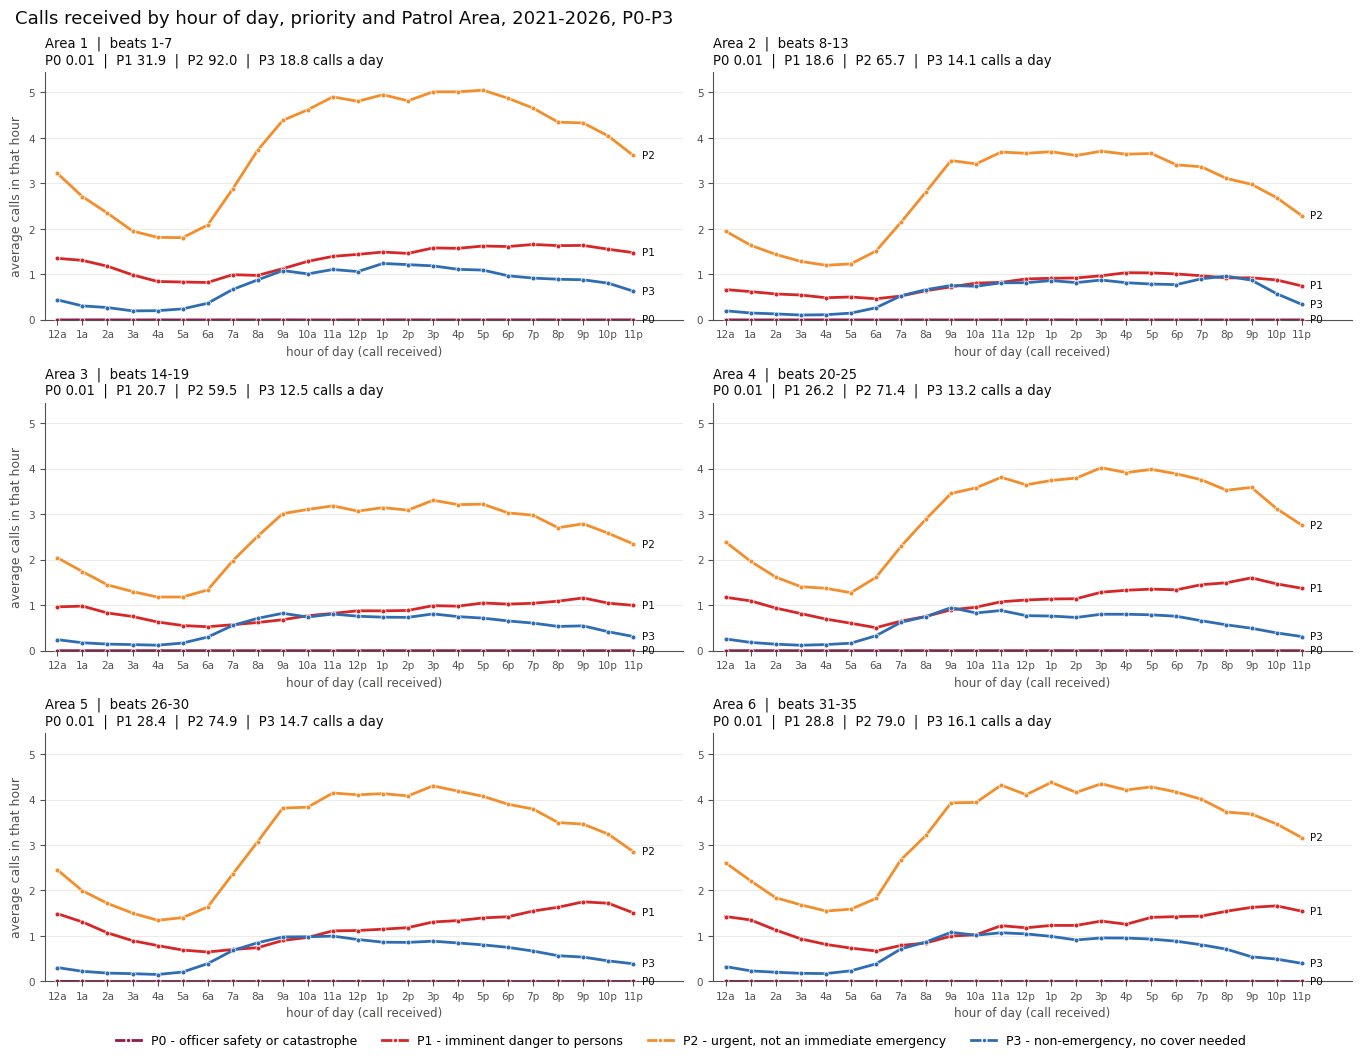

calls per day,P0 - officer safety or catastrophe,P1 - imminent danger to persons,"P2 - urgent, not an immediate emergency","P3 - non-emergency, no cover needed"
area,,,,
1,0.0,31.9,92.0,18.8
2,0.0,18.6,65.7,14.1
3,0.0,20.7,59.5,12.5
4,0.0,26.2,71.4,13.2
5,0.0,28.4,74.9,14.7
6,0.0,28.8,79.0,16.1


In [10]:
by_priority = calls.groupby(["area", "hour", "priority"]).size().unstack("priority").reindex(columns=PRIORITIES).fillna(0) / calls["date"].nunique()

fig, axes = plt.subplots(3, 2, figsize=(13.5, 10.5), sharex=True, sharey=True, layout="constrained")
for ax, a in zip(axes.flat, AREA_BEATS):
    v = by_priority.loc[a].reindex(range(24)).fillna(0)
    for p in PRIORITIES:
        ax.plot(range(24), v[p], color=PRIORITY_COLORS[p], lw=2, marker="o", ms=3.5, mec="white", mew=.5, zorder=3)
    end_labels(ax, [(v[p].iloc[23], f"P{p}") for p in PRIORITIES], by_priority.max().max() * .06)
    ax.set_title(f"Area {a}  |  beats {AREA_BEATS[a]}\n" + "  |  ".join(f"P{p} {v[p].sum():.{2 if p == 0 else 1}f}" for p in PRIORITIES) + " calls a day",
                 loc="left", fontsize=9.5, color=INK)
    hour_axis(ax)
    ax.set_xticks(range(24), HOUR_LABEL)
    ax.set_xlim(-.5, 25)
    ax.set_ylim(0, by_priority.max().max() * 1.08)
    style(ax, 7.5)
    ax.tick_params(labelbottom=True, labelleft=True)
for ax in axes[:, 0]:
    ax.set_ylabel("average calls in that hour", fontsize=9, color=MUTED)
fig.legend(handles=[plt.Line2D([], [], color=PRIORITY_COLORS[p], lw=2, marker="o", ms=3.5, mec="white", label=PRIORITY_LABELS[p]) for p in PRIORITIES],
           loc="outside lower center", ncol=4, fontsize=9, frameon=False)
fig.suptitle("Calls received by hour of day, priority and Patrol Area, 2021-2026, P0-P3", ha="left", x=.007, fontsize=13, color=INK)
plt.show()

by_priority.rename(columns=PRIORITY_LABELS).groupby("area").sum().round(1).rename_axis(columns="calls per day")